# Comparação entre os modelos — YOLO11s-cls × EfficientNet-B0
### Classificação de tumor cerebral em RM · glioma · meningioma · notumor · pituitary

Este notebook contém **apenas a comparação** dos dois modelos, nas mesmas imagens, com os mesmos critérios. A validação completa de cada modelo, isoladamente, está nas pastas `01_YOLO11s-cls` e `02_EfficientNet-B0`; aqui só entra o que exige olhar os dois juntos.

| # | Figura | Pergunta |
|---|---|---|
| 1 | Métricas lado a lado | Qual acerta mais, em validação e teste? |
| 2 | ROC e Precisão-Recall sobrepostas | Qual separa melhor as classes? |
| 3 | Log-loss comparado | Qual tem probabilidades melhores? |
| 4 | Acurácia treino × validação × teste e teste limpo | Qual generaliza melhor? O vazamento favorece algum? |
| 5 | Acurácia por época (os dois) | Como cada um aprendeu ao longo do treino? |
| 6 | Loss e taxa de aprendizado | Os treinos foram parecidos? |
| 7 | Confusões e métricas por classe | Onde cada um erra? |
| 8 | Calibração e predição seletiva | Qual tem confiança mais honesta? |
| 9 | Visão clínica | Qual deixa passar menos tumores? |
| 10 | Estatística pareada | A diferença é real ou ruído? |
| 11 | Robustez | Qual aguenta melhor perturbações? |
| 12–13 | Mapas de calor (Grad-CAM) | Onde cada um olha? (**mantidos exatamente como já aprovados**) |
| 14 | Erros: quem erra onde | Os erros coincidem? |
| 15 | Eficiência | Custo, tamanho e velocidade |
| 16 | Checklist lado a lado | Qual passa em mais critérios? |
| 17 | Placar e conclusão | Resumo final |

> **Pré-requisito:** executar antes os notebooks das pastas `01_YOLO11s-cls` e `02_EfficientNet-B0` (eles geram as probabilidades em cache e os resultados lidos aqui). Execução ≈ 3–5 min.

In [1]:
!pip install -q scikit-learn scipy matplotlib pandas seaborn pillow

## 0. Preparação

In [2]:
import json, math, shutil, hashlib, warnings, glob, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
from scipy.spatial.distance import cdist
from scipy.stats import binomtest, norm
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score, matthews_corrcoef, cohen_kappa_score,
                             log_loss, roc_auc_score, roc_curve, auc, precision_recall_curve, average_precision_score, confusion_matrix)
from IPython.display import display

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 13, "axes.titlesize": 15, "axes.labelsize": 13, "legend.fontsize": 11, "figure.dpi": 100, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})

SEED, N_BOOT, DUP_LIM = 42, 2000, 2.0
def achar_base():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "Treinamento_CNN").exists() and (cand / "Treinamento_YOLO").exists(): return cand
    return p
BASE = achar_base(); V = BASE / "Validacoes"
PASTA_DADOS = BASE / "Treinamento_CNN" / "Tumor-Cerebral-1"; PASTA_CNN = BASE / "Treinamento_CNN" / "runs"; PASTA_YOLO_RUN = BASE / "Treinamento_YOLO" / "runs" / "classify" / "runs" / "yolo11s_lung_v2"
CACHE = V / "_compartilhado" / "cache"; PY, PC = V / "01_YOLO11s-cls", V / "02_EfficientNet-B0"; PASTA = V / "03_Comparacao_YOLO_vs_CNN"; FIG = PASTA / "figuras"; TAB = PASTA / "tabelas"; FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(exist_ok=True)
HEAT = V / "_anteriores" / "Kit_Apresentacao" / "figuras"       # origem dos 2 mapas de calor aprovados

NOME_Y, NOME_C = "YOLO11s-cls", "EfficientNet-B0"; MODELOS = [NOME_Y, NOME_C]; COR = {NOME_Y: "#d95f02", NOME_C: "#1b9e77"}; PAST = {NOME_Y: PY, NOME_C: PC}
NOME_S = {"train": "treino", "val": "validação", "test": "teste"}; SPL3 = ["train", "val", "test"]; SV = ["val", "test"]
falt = [str(p) for p in [CACHE, PY / "numeros_chave.json", PC / "numeros_chave.json", PY / "checklist.json", PC / "checklist.json", PY / "tabelas" / "12_robustez.csv", PC / "tabelas" / "12_robustez.csv"] if not Path(p).exists()]
if falt: raise FileNotFoundError("Execute antes os notebooks das pastas 01_YOLO11s-cls e 02_EfficientNet-B0. Faltando:\n" + "\n".join(falt))
NK = {m: json.loads((PAST[m] / "numeros_chave.json").read_text(encoding="utf-8")) for m in MODELOS}; CK = {m: json.loads((PAST[m] / "checklist.json").read_text(encoding="utf-8")) for m in MODELOS}
meta = json.loads((PASTA_CNN / "efficientnet_b0_meta.json").read_text(encoding="utf-8")); TMAX = meta["epocas_treinadas"]
hist_c = pd.read_csv(PASTA_CNN / "efficientnet_b0_historico.csv"); hist_y = pd.read_csv(PASTA_YOLO_RUN / "results.csv"); hist_y.columns = [c.strip() for c in hist_y.columns]
hist_c["lr"] = [0.5 * 3e-4 * (1 + math.cos(math.pi * (e - 1) / TMAX)) for e in hist_c["epoca"]]   # LR da CNN reconstruído (cosine, T_max = épocas treinadas)

LEG, NUM, TABS = [], {}, []
def salvar(nome, titulo, mostra, ler, resultado):
    plt.savefig(FIG / nome, bbox_inches="tight", facecolor="white"); plt.show(); LEG.append(dict(arquivo=nome, titulo=titulo, mostra=mostra, ler=ler, resultado=resultado)); print("salvo:", nome)
def fmt(v): return (f"{v:.4f}" if abs(v) < 100 else f"{v:.1f}") if isinstance(v, (float, np.floating)) else str(v)
def reg_tab(nome, df, titulo, index=True):
    d = df.reset_index() if index else df.copy(); d.to_csv(TAB / f"{nome}.csv", index=False, encoding="utf-8-sig")
    TABS.append(dict(nome=nome, titulo=titulo, cols=[str(c) for c in d.columns], rows=[[fmt(v) for v in r] for r in d.values.tolist()])); display(df.round(4) if hasattr(df, "round") else df)
print("Base:", BASE)

Base: C:\Users\pedro.almeida\Downloads\Trabalho Faculdade


In [3]:
EXT = (".jpg", ".jpeg", ".png", ".bmp")
def listar(split):
    cls = sorted(d.name for d in (PASTA_DADOS / split).iterdir() if d.is_dir()); ar, y = [], []
    for i, c in enumerate(cls):
        for f in sorted(p for p in (PASTA_DADOS / split / c).iterdir() if p.suffix.lower() in EXT): ar.append(str(f)); y.append(i)
    return cls, ar, np.array(y)
PS = {"train": "train", "val": "valid", "test": "test"}; CAM, Y = {}, {}
for s in SPL3: CLASSES, CAM[s], Y[s] = listar(PS[s])
NC = len(CLASSES); i_nt = CLASSES.index("notumor")
def carregar(pre, s):
    fs = sorted(glob.glob(str(CACHE / f"{pre}_{s}_*_{len(Y[s])}.npy")), key=lambda f: Path(f).stat().st_mtime)
    if not fs: raise FileNotFoundError(f"Probabilidades em cache não encontradas ({pre}, {s}). Execute os notebooks dos modelos.")
    return np.load(fs[-1])
PROB = {NOME_Y: {s: carregar("yolo", s) for s in SPL3}, NOME_C: {s: carregar("cnn", s) for s in SPL3}}; PRED = {m: {s: PROB[m][s].argmax(1) for s in SPL3} for m in MODELOS}
for m in MODELOS:
    a = accuracy_score(Y["test"], PRED[m]["test"]); ref = NK[m]["acc_teste"]; print(f"{m}: acurácia no teste {a:.4f} | registrada na pasta do modelo {ref:.4f} | {'OK' if abs(a-ref) < 1e-3 else 'DIFERE!'}")
    assert abs(a - ref) < 1e-3, "As probabilidades em cache não batem com a validação do modelo: reexecute o notebook do modelo."

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); a = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)); return (c - a) / d, (c + a) / d
def ece(y, P, bins=10):
    conf, ok = P.max(1), (P.argmax(1) == y).astype(float); e = 0.0
    for lo, hi in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.any(): e += mk.mean() * abs(ok[mk].mean() - conf[mk].mean())
    return e
def brier(y, P): return float(np.mean(np.sum((P - np.eye(NC)[y]) ** 2, 1)))
def perda(y, P): return -np.log(np.clip(P[np.arange(len(y)), y], 1e-12, 1))
def roc_macro(y, P):
    Yb = np.eye(NC)[y]; f = np.unique(np.concatenate([roc_curve(Yb[:, i], P[:, i])[0] for i in range(NC)])); t = np.mean([np.interp(f, *roc_curve(Yb[:, i], P[:, i])[:2]) for i in range(NC)], axis=0); return f, t, auc(f, t)
acc = lambda m, s: accuracy_score(Y[s], PRED[m][s]); pp = lambda x, d=1: f"{100*x:.{d}f}%".replace(".", ",")
def metricas(y, P):
    p = P.argmax(1)
    return {"Acurácia": accuracy_score(y, p), "Acurácia balanceada": balanced_accuracy_score(y, p), "F1 macro": f1_score(y, p, average="macro"), "MCC": matthews_corrcoef(y, p), "Kappa": cohen_kappa_score(y, p),
            "AUC macro (OvR)": roc_auc_score(y, P, multi_class="ovr"), "AP macro": average_precision_score(np.eye(NC)[y], P, average="macro"), "Log-loss": log_loss(y, P, labels=list(range(NC))), "Brier": brier(y, P), "ECE": ece(y, P), "Erros (nº)": int((p != y).sum())}
lead = lambda a, b, maior=True: (NOME_C if a > b else NOME_Y) if maior else (NOME_C if a < b else NOME_Y)

YOLO11s-cls: acurácia no teste 0.9794 | registrada na pasta do modelo 0.9794 | OK
EfficientNet-B0: acurácia no teste 0.9912 | registrada na pasta do modelo 0.9912 | OK


## Figura 1 — Métricas lado a lado

,treino — YOLO,treino — CNN,validação — YOLO,validação — CNN,teste — YOLO,teste — CNN
Acurácia,0.9994,0.9996,0.9710,0.9884,0.9794,0.9912
Acurácia balanceada,0.9994,0.9996,0.9703,0.9881,0.9796,0.9913
F1 macro,0.9994,0.9996,0.9703,0.9882,0.9794,0.9914
MCC,0.9992,0.9994,0.9614,0.9845,0.9726,0.9882
Kappa,0.9992,0.9994,0.9613,0.9845,0.9726,0.9882
AUC macro (OvR),1.0000,1.0000,0.9966,0.9988,0.9984,0.9999
AP macro,1.0000,1.0000,0.9923,0.9970,0.9959,0.9996
Log-loss,0.0094,0.0010,0.1218,0.0819,0.0780,0.0339
Brier,0.0027,0.0006,0.0487,0.0237,0.0324,0.0158
ECE,0.0074,0.0004,0.0137,0.0116,0.0050,0.0087


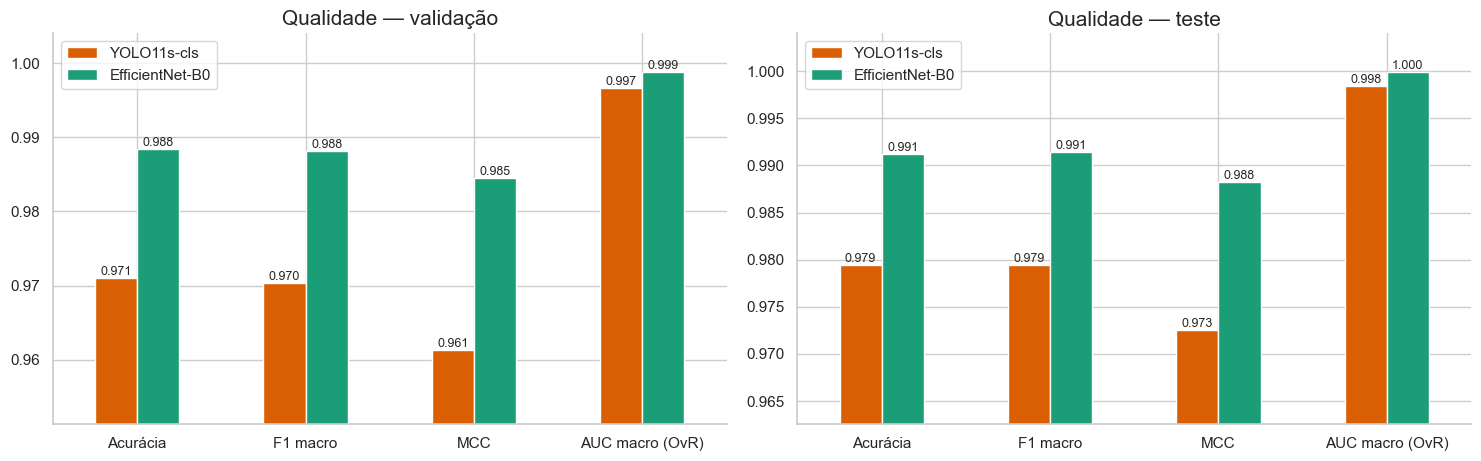

salvo: 01_metricas_lado_a_lado.png


In [4]:
MET = pd.DataFrame({(NOME_S[s], m): metricas(Y[s], PROB[m][s]) for s in SPL3 for m in MODELOS}); reg_tab("01_metricas", MET.set_axis([f"{a} — {b}" for a, b in MET.columns], axis=1).rename(columns=lambda c: c.replace("YOLO11s-cls", "YOLO").replace("EfficientNet-B0", "CNN")), "Métricas por conjunto e modelo")
chave = ["Acurácia", "F1 macro", "MCC", "AUC macro (OvR)"]; fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for a, s in zip(ax, SV):
    d = pd.DataFrame({m: MET[(NOME_S[s], m)].loc[chave] for m in MODELOS}); d.plot.bar(ax=a, rot=0, color=[COR[m] for m in MODELOS]); a.set_ylim(max(.9, d.min().min() - .01), 1.004); a.set_title(f"Qualidade — {NOME_S[s]}")
    for c in a.containers: a.bar_label(c, fmt="%.3f", fontsize=9)
plt.tight_layout(); t, v = "teste", "validação"
for m in MODELOS: NUM[f"acc_teste_{m}"] = round(MET[(t, m)]["Acurácia"], 4); NUM[f"acc_val_{m}"] = round(MET[(v, m)]["Acurácia"], 4); NUM[f"f1_teste_{m}"] = round(MET[(t, m)]["F1 macro"], 4); NUM[f"mcc_teste_{m}"] = round(MET[(t, m)]["MCC"], 4); NUM[f"erros_teste_{m}"] = int(MET[(t, m)]["Erros (nº)"]); NUM[f"erros_val_{m}"] = int(MET[(v, m)]["Erros (nº)"])
salvar("01_metricas_lado_a_lado.png", "Métricas lado a lado: acurácia, F1, MCC e AUC",
       "Acurácia, F1 macro, MCC e AUC macro de cada modelo em validação e teste, nas mesmas imagens.",
       "Barras mais altas são melhores. O eixo vertical é ampliado para mostrar diferenças pequenas, que devem ser lidas junto com os intervalos de confiança da figura 10.",
       f"No teste ({len(Y['test'])} imagens): {NOME_C} acerta {pp(NUM['acc_teste_'+NOME_C])} ({NUM['erros_teste_'+NOME_C]} erros) e {NOME_Y} {pp(NUM['acc_teste_'+NOME_Y])} ({NUM['erros_teste_'+NOME_Y]} erros). Na validação: {pp(NUM['acc_val_'+NOME_C])} e {pp(NUM['acc_val_'+NOME_Y])}. F1 macro no teste: {NUM['f1_teste_'+NOME_C]:.4f} (CNN) e {NUM['f1_teste_'+NOME_Y]:.4f} (YOLO); MCC: {NUM['mcc_teste_'+NOME_C]:.4f} e {NUM['mcc_teste_'+NOME_Y]:.4f}.")

## Figura 2 — ROC e Precisão-Recall sobrepostas

,YOLO11s-cls,EfficientNet-B0
glioma,0.9974,0.9999
meningioma,0.9971,0.9999
notumor,0.9999,0.9999
pituitary,0.9991,0.9998


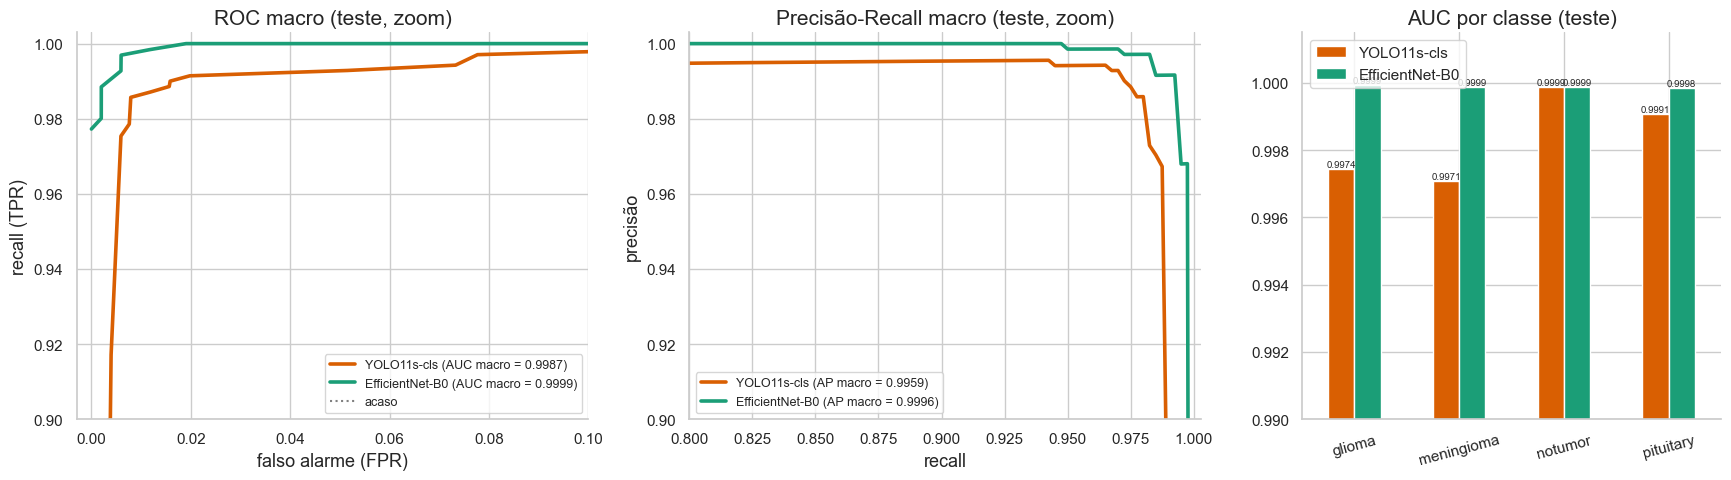

salvo: 02_roc_pr_sobrepostas.png


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17.5, 5), gridspec_kw={"width_ratios": [1.1, 1.1, .9]}); AUCM, APM = {}, {}; grade = np.linspace(0, 1, 401)
for m in MODELOS:
    f, t_, a_ = roc_macro(Y["test"], PROB[m]["test"]); AUCM[m] = a_; ax[0].plot(f, t_, color=COR[m], lw=2.6, label=f"{m} (AUC macro = {a_:.4f})"); Yb = np.eye(NC)[Y["test"]]; cs = []
    for i in range(NC): pr_, rc_, _ = precision_recall_curve(Yb[:, i], PROB[m]["test"][:, i]); cs.append(np.interp(grade, rc_[::-1], pr_[::-1]))
    APM[m] = average_precision_score(Yb, PROB[m]["test"], average="macro"); ax[1].plot(grade, np.mean(cs, 0), color=COR[m], lw=2.6, label=f"{m} (AP macro = {APM[m]:.4f})")
ax[0].plot([0, 1], [0, 1], ":", color="gray", label="acaso"); ax[0].set_xlim(-.003, .1); ax[0].set_ylim(.9, 1.003); ax[0].set_xlabel("falso alarme (FPR)"); ax[0].set_ylabel("recall (TPR)"); ax[0].set_title("ROC macro (teste, zoom)"); ax[0].legend(loc="lower right", fontsize=9)
ax[1].set_xlim(.8, 1.003); ax[1].set_ylim(.9, 1.003); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precisão"); ax[1].set_title("Precisão-Recall macro (teste, zoom)"); ax[1].legend(loc="lower left", fontsize=9)
ac = pd.DataFrame({m: [roc_auc_score(Y["test"] == i, PROB[m]["test"][:, i]) for i in range(NC)] for m in MODELOS}, index=CLASSES); ac.plot.bar(ax=ax[2], rot=15, color=[COR[m] for m in MODELOS]); ax[2].set_ylim(.99, 1.0015); ax[2].set_title("AUC por classe (teste)")
for c in ax[2].containers: ax[2].bar_label(c, fmt="%.4f", fontsize=7)
plt.tight_layout(); reg_tab("02_auc_por_classe", ac.round(5).assign(), "AUC por classe (teste)")
for m in MODELOS: NUM[f"auc_macro_{m}"] = round(AUCM[m], 4); NUM[f"ap_macro_{m}"] = round(APM[m], 4); NUM[f"menor_auc_{m}"] = round(float(ac[m].min()), 4); NUM[f"classe_menor_auc_{m}"] = ac[m].idxmin()
salvar("02_roc_pr_sobrepostas.png", "Curvas ROC e Precisão-Recall dos dois modelos",
       "ROC macro e Precisão-Recall macro (média das 4 classes um-contra-todos) dos dois modelos no teste, em zoom, e a AUC por classe.",
       "Quanto mais a ROC colar no canto superior esquerdo (e a PR no superior direito), melhor a separação das classes. Ordenar bem (AUC) é diferente de decidir bem num corte e de ter probabilidade honesta (figuras 3 e 8).",
       f"AUC macro no teste: {NOME_C} {AUCM[NOME_C]:.4f} e {NOME_Y} {AUCM[NOME_Y]:.4f}; AP macro {APM[NOME_C]:.4f} e {APM[NOME_Y]:.4f}. Menor AUC por classe: {NOME_C} {NUM['menor_auc_'+NOME_C]:.4f} ({NUM['classe_menor_auc_'+NOME_C]}) e {NOME_Y} {NUM['menor_auc_'+NOME_Y]:.4f} ({NUM['classe_menor_auc_'+NOME_Y]}).")

## Figura 3 — Log-loss comparado

,treino,validação,teste
YOLO11s-cls,0.0094,0.1218,0.0780
EfficientNet-B0,0.0010,0.0819,0.0339


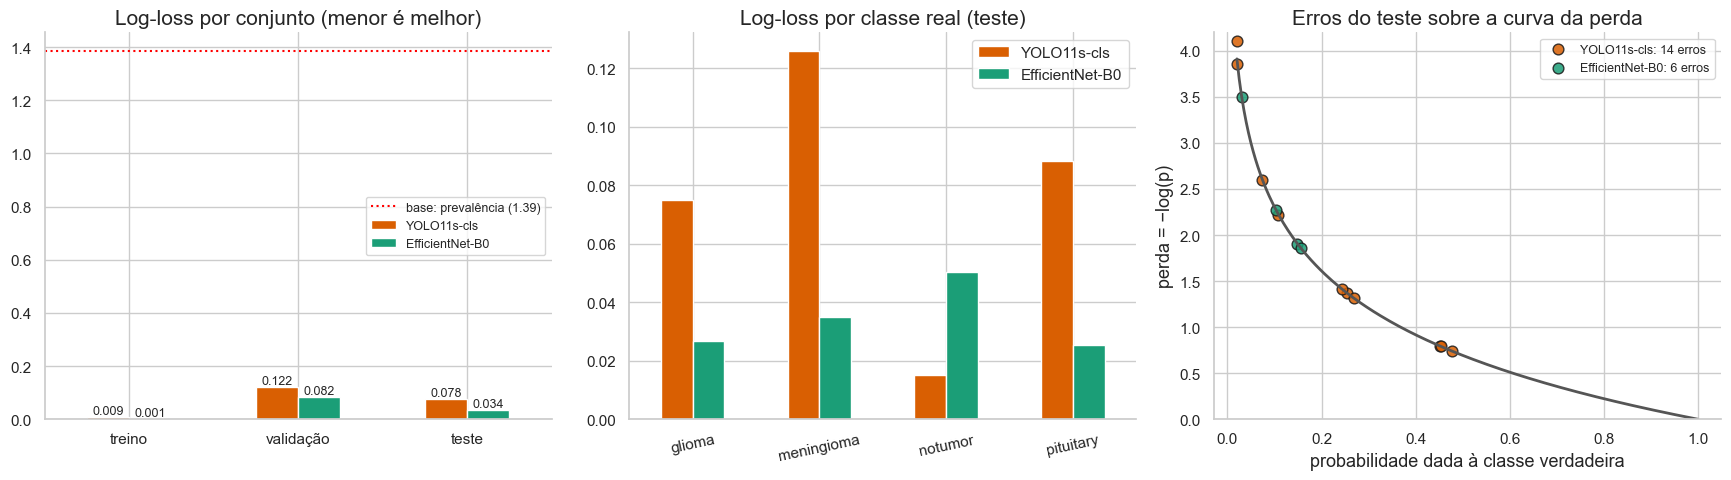

salvo: 03_log_loss_comparado.png


In [6]:
prev = np.bincount(Y["train"]) / len(Y["train"]); ll_prev = log_loss(Y["test"], np.tile(prev, (len(Y["test"]), 1)), labels=list(range(NC)))
LL = pd.DataFrame({NOME_S[s]: {m: log_loss(Y[s], PROB[m][s], labels=list(range(NC))) for m in MODELOS} for s in SPL3}); fig, ax = plt.subplots(1, 3, figsize=(17.5, 5))
LL.T.plot.bar(ax=ax[0], rot=0, color=[COR[m] for m in MODELOS]); ax[0].axhline(ll_prev, color="red", ls=":", label=f"base: prevalência ({ll_prev:.2f})"); ax[0].set_title("Log-loss por conjunto (menor é melhor)"); ax[0].legend(fontsize=9)
for c in ax[0].containers: ax[0].bar_label(c, fmt="%.3f", fontsize=9)
llc = pd.DataFrame({m: [perda(Y["test"], PROB[m]["test"])[Y["test"] == i].mean() for i in range(NC)] for m in MODELOS}, index=CLASSES); llc.plot.bar(ax=ax[1], rot=12, color=[COR[m] for m in MODELOS]); ax[1].set_title("Log-loss por classe real (teste)")
pg = np.linspace(.02, 1, 200); ax[2].plot(pg, -np.log(pg), color="#555", lw=2)
for m in MODELOS:
    pt_ = PROB[m]["test"][np.arange(len(Y["test"])), Y["test"]]; err = pt_[PRED[m]["test"] != Y["test"]]; ax[2].scatter(np.clip(err, .02, 1), -np.log(np.clip(err, 1e-12, 1)), color=COR[m], s=60, edgecolor="k", alpha=.85, label=f"{m}: {len(err)} erros")
ax[2].set_ylim(0, 4.2); ax[2].set_xlabel("probabilidade dada à classe verdadeira"); ax[2].set_ylabel("perda = −log(p)"); ax[2].set_title("Erros do teste sobre a curva da perda"); ax[2].legend(fontsize=9); plt.tight_layout()
reg_tab("03_logloss", LL.T.rename_axis("modelo").T if False else LL, "Log-loss por conjunto")
for m in MODELOS:
    l = perda(Y["test"], PROB[m]["test"]); k5 = max(1, int(.05 * len(l))); NUM[f"logloss_teste_{m}"] = round(LL.loc[m, "teste"], 4); NUM[f"logloss_val_{m}"] = round(LL.loc[m, "validação"], 4); NUM[f"logloss_conc5_{m}"] = round(100 * np.sort(l)[::-1][:k5].sum() / l.sum(), 1)
NUM["logloss_prevalencia"] = round(ll_prev, 4)
salvar("03_log_loss_comparado.png", "Log-loss: qual modelo tem probabilidades melhores?",
       "Log-loss de cada modelo em treino, validação e teste contra a base de prever a prevalência, o log-loss por classe e os erros do teste sobre a curva −log(p).",
       "Menor é melhor. Errar com certeza (probabilidade baixa na classe certa) custa muito mais do que errar com dúvida; os pontos mais altos da curva são erros confiantes.",
       f"Log-loss no teste: {NOME_C} {NUM['logloss_teste_'+NOME_C]:.3f} e {NOME_Y} {NUM['logloss_teste_'+NOME_Y]:.3f}, contra {ll_prev:.2f} da base. Os 5% de imagens de maior perda respondem por {NUM['logloss_conc5_'+NOME_C]:.0f}% (CNN) e {NUM['logloss_conc5_'+NOME_Y]:.0f}% (YOLO) do log-loss do teste.")

## Figura 4 — Acurácia treino × validação × teste e efeito do vazamento
Barras com intervalo de Wilson 95%, o gap de generalização e o **teste limpo** (sem as imagens com quase-duplicata no treino/validação, medidas pela diferença de pixel em miniaturas 32×32). O treino é medido sem augmentation.

,YOLO11s-cls,EfficientNet-B0
treino,0.9994,0.9996
validação,0.9710,0.9884
teste,0.9794,0.9912


,YOLO11s-cls,EfficientNet-B0
teste completo,0.9794,0.9912
teste limpo (n=570),0.9772,0.9895


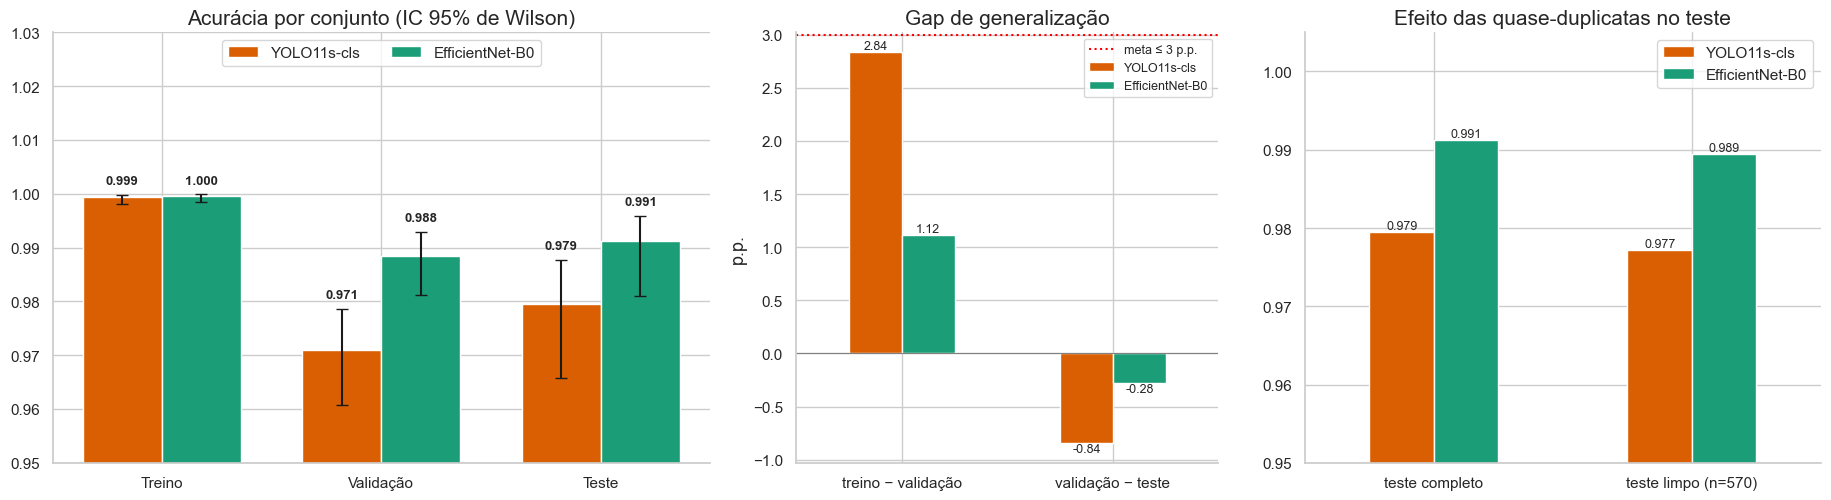

salvo: 04_acuracia_treino_val_teste.png


In [7]:
X32 = {s: np.stack([np.asarray(Image.open(p).convert("L").resize((32, 32), Image.BILINEAR), dtype=np.float32).ravel() for p in CAM[s]]) for s in SPL3}
nn = lambda a, b: (cdist(X32[a], X32[b], "cityblock") / 1024).min(1); dup_tt, dup_tv = nn("test", "train") <= DUP_LIM, nn("test", "val") <= DUP_LIM; LIMPO = ~(dup_tt | dup_tv)
fig, ax = plt.subplots(1, 3, figsize=(18.5, 5.2), gridspec_kw={"width_ratios": [1.4, .9, 1.1]}); w = .36; x = np.arange(3)
for j, m in enumerate(MODELOS):
    v_ = np.array([acc(m, s) for s in SPL3]); ci = np.array([wilson(int((PRED[m][s] == Y[s]).sum()), len(Y[s])) for s in SPL3])
    ax[0].bar(x + (j - .5) * w, v_, w, color=COR[m], label=m, yerr=[v_ - ci[:, 0], ci[:, 1] - v_], capsize=4)
    for xi, vi, hi in zip(x + (j - .5) * w, v_, ci[:, 1]): ax[0].text(xi, hi + .002, f"{vi:.3f}", ha="center", fontsize=9.5, fontweight="bold")
ax[0].set_xticks(x); ax[0].set_xticklabels([NOME_S[s].capitalize() for s in SPL3]); ax[0].set_ylim(.95, 1.03); ax[0].set_title("Acurácia por conjunto (IC 95% de Wilson)"); ax[0].legend(loc="upper center", ncol=2)
G = pd.DataFrame({m: [100 * (acc(m, "train") - acc(m, "val")), 100 * (acc(m, "val") - acc(m, "test"))] for m in MODELOS}, index=["treino − validação", "validação − teste"]); G.plot.bar(ax=ax[1], rot=0, color=[COR[m] for m in MODELOS]); ax[1].axhline(0, color="gray", lw=.8)
ax[1].axhline(3, color="red", ls=":", label="meta ≤ 3 p.p."); ax[1].set_ylabel("p.p."); ax[1].set_title("Gap de generalização"); ax[1].legend(fontsize=9)
for c in ax[1].containers: ax[1].bar_label(c, fmt="%.2f", fontsize=9)
accl = pd.DataFrame({m: [acc(m, "test"), accuracy_score(Y["test"][LIMPO], PRED[m]["test"][LIMPO])] for m in MODELOS}, index=["teste completo", f"teste limpo (n={int(LIMPO.sum())})"]); accl.plot.bar(ax=ax[2], rot=0, color=[COR[m] for m in MODELOS]); ax[2].set_ylim(.95, 1.005); ax[2].set_title("Efeito das quase-duplicatas no teste")
for c in ax[2].containers: ax[2].bar_label(c, fmt="%.3f", fontsize=9)
plt.tight_layout(); reg_tab("04_acuracia_por_conjunto", pd.DataFrame({m: {NOME_S[s]: acc(m, s) for s in SPL3} for m in MODELOS}), "Acurácia por conjunto"); reg_tab("04_teste_limpo", accl, "Acurácia no teste completo e no teste limpo")
for m in MODELOS: NUM[f"acc_treino_{m}"] = round(acc(m, "train"), 4); NUM[f"gap_treino_val_pp_{m}"] = round(G.loc["treino − validação", m], 2); NUM[f"gap_val_teste_pp_{m}"] = round(G.loc["validação − teste", m], 2); NUM[f"acc_teste_limpo_{m}"] = round(accl.iloc[1][m], 4)
NUM.update(n_teste_limpo=int(LIMPO.sum()), pct_teste_quase_duplicata=round(100 * dup_tt.mean(), 1), imagens_teste_quase_duplicata=int(dup_tt.sum()))
salvar("04_acuracia_treino_val_teste.png", "Acurácia em treino, validação e teste: qual modelo generaliza melhor?",
       "Acurácia de cada modelo nos três conjuntos com intervalo de confiança, o gap treino−validação e validação−teste em pontos percentuais e a acurácia no teste completo contra o teste limpo (sem quase-duplicatas do treino).",
       "Treino muito acima da validação indica sobreajuste. Validação próxima do teste indica estimativa estável. Se a acurácia no teste limpo for próxima à do completo, o vazamento por quase-duplicatas favoreceu pouco.",
       f"Gap treino−validação: {NOME_C} {NUM['gap_treino_val_pp_'+NOME_C]:.2f} p.p. e {NOME_Y} {NUM['gap_treino_val_pp_'+NOME_Y]:.2f} p.p. (ambos abaixo da meta de 3 p.p.); validação−teste: {NUM['gap_val_teste_pp_'+NOME_C]:+.2f} e {NUM['gap_val_teste_pp_'+NOME_Y]:+.2f} p.p. {NUM['imagens_teste_quase_duplicata']} imagens de teste ({NUM['pct_teste_quase_duplicata']}%) têm quase-duplicata no treino; no teste limpo ({NUM['n_teste_limpo']} imagens) a acurácia é {NUM['acc_teste_limpo_'+NOME_C]:.3f} (CNN) e {NUM['acc_teste_limpo_'+NOME_Y]:.3f} (YOLO), contra {NUM['acc_teste_'+NOME_C]:.3f} e {NUM['acc_teste_'+NOME_Y]:.3f} no teste completo.")

## Figura 5 — Acurácia por época dos dois modelos

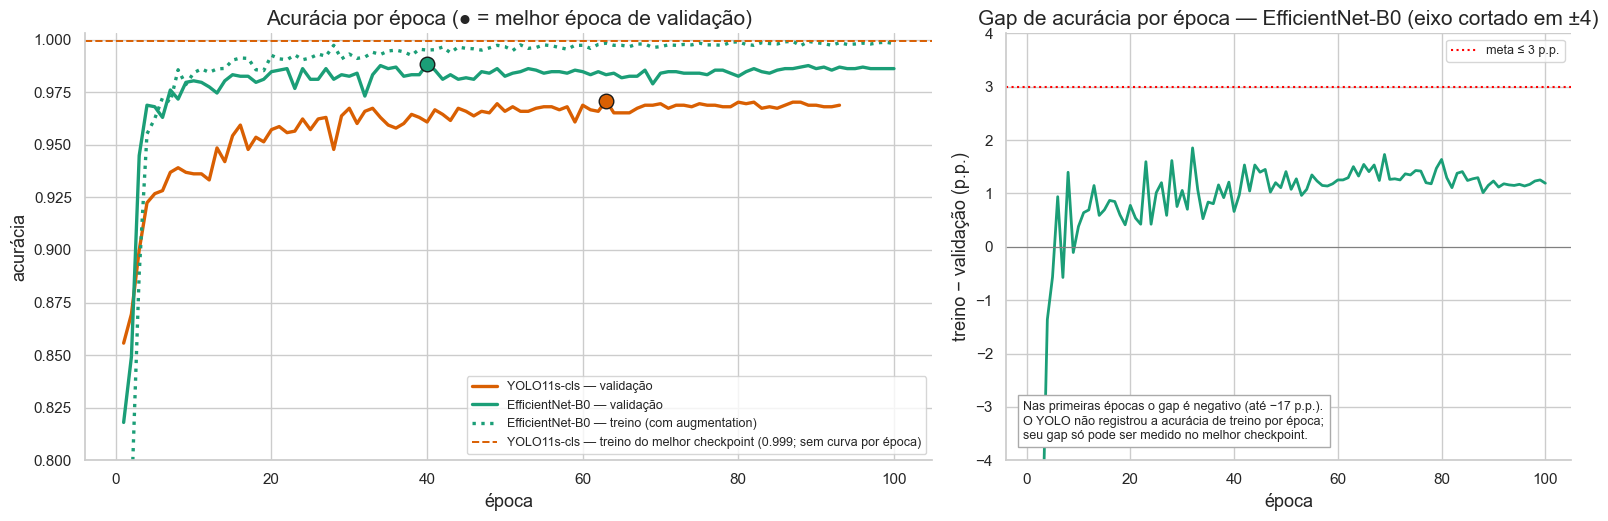

salvo: 05_acuracia_por_epoca.png


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1.5, 1]})
ey, vy = hist_y["epoch"].values, hist_y["metrics/accuracy_top1"].values; ec, vc, tc = hist_c["epoca"].values, hist_c["acc_val"].values, hist_c["acc_treino"].values
ax[0].plot(ey, vy, color=COR[NOME_Y], lw=2.4, label=f"{NOME_Y} — validação"); ax[0].plot(ec, vc, color=COR[NOME_C], lw=2.4, label=f"{NOME_C} — validação"); ax[0].plot(ec, tc, color=COR[NOME_C], ls=":", lw=2.4, label=f"{NOME_C} — treino (com augmentation)")
ax[0].axhline(acc(NOME_Y, "train"), color=COR[NOME_Y], ls="--", lw=1.4, label=f"{NOME_Y} — treino do melhor checkpoint ({acc(NOME_Y,'train'):.3f}; sem curva por época)")
for e_, v_, m in ((ey, vy, NOME_Y), (ec, vc, NOME_C)): bb = int(v_.argmax()); ax[0].scatter([e_[bb]], [v_[bb]], s=110, color=COR[m], edgecolor="k", zorder=5)
ax[0].set_ylim(.8, 1.003); ax[0].set_xlabel("época"); ax[0].set_ylabel("acurácia"); ax[0].set_title("Acurácia por época (● = melhor época de validação)"); ax[0].legend(loc="lower right", fontsize=9)
ax[1].plot(ec, 100 * (tc - vc), color=COR[NOME_C], lw=2); ax[1].axhline(0, color="gray", lw=.8); ax[1].axhline(3, color="red", ls=":", label="meta ≤ 3 p.p."); ax[1].set_ylim(-4, 4); ax[1].set_xlabel("época"); ax[1].set_ylabel("treino − validação (p.p.)"); ax[1].set_title(f"Gap de acurácia por época — {NOME_C} (eixo cortado em ±4)"); ax[1].legend(fontsize=9, loc="upper right")
ax[1].text(.03, .05, "Nas primeiras épocas o gap é negativo (até −17 p.p.).\nO YOLO não registrou a acurácia de treino por época;\nseu gap só pode ser medido no melhor checkpoint.", transform=ax[1].transAxes, fontsize=9, bbox=dict(fc="white", ec="#aaa")); plt.tight_layout()
by, bc = int(vy.argmax()), int(vc.argmax()); g10 = float(np.mean(100 * (tc[-10:] - vc[-10:])))
NUM.update(melhor_epoca_YOLO=int(ey[by]), melhor_epoca_CNN=int(ec[bc]), epocas_YOLO=int(len(ey)), epocas_CNN=int(len(ec)), acc_val_melhor_YOLO=round(float(vy[by]), 4), acc_val_melhor_CNN=round(float(vc[bc]), 4), gap_epoca_cnn_ultimas10_pp=round(g10, 2))
salvar("05_acuracia_por_epoca.png", "Acurácia de treino e de validação por época nos dois modelos",
       "Acurácia de validação de cada modelo a cada época, a acurácia de treino por época da CNN (registrada no treino, com augmentation) e a acurácia de treino do melhor checkpoint do YOLO (medida depois, sem augmentation), com o gap da CNN por época.",
       "Curvas de treino e validação próximas e estáveis indicam boa generalização. O gap de acurácia por época só existe para a CNN, pois o treino do YOLO não gravou a acurácia de treino por época.",
       f"YOLO: {len(ey)} épocas, melhor na {ey[by]}ª (validação {vy[by]:.3f}). CNN: {len(ec)} épocas, melhor na {ec[bc]}ª (validação {vc[bc]:.3f}); gap médio de acurácia nas últimas 10 épocas {g10:.2f} p.p. A CNN atinge a faixa de 0,98 de validação em poucas épocas e o YOLO converge mais devagar, estabilizando em torno de 0,97.")

## Figura 6 — Loss e taxa de aprendizado

,YOLO11s-cls,EfficientNet-B0
Épocas,93.0000,100.0000
Melhor época,63.0000,40.0000
Acurácia de validação (melhor),0.9710,0.9884
Tempo de treino (min),801.2000,230.5000
Loss de treino final,0.0137,0.0039


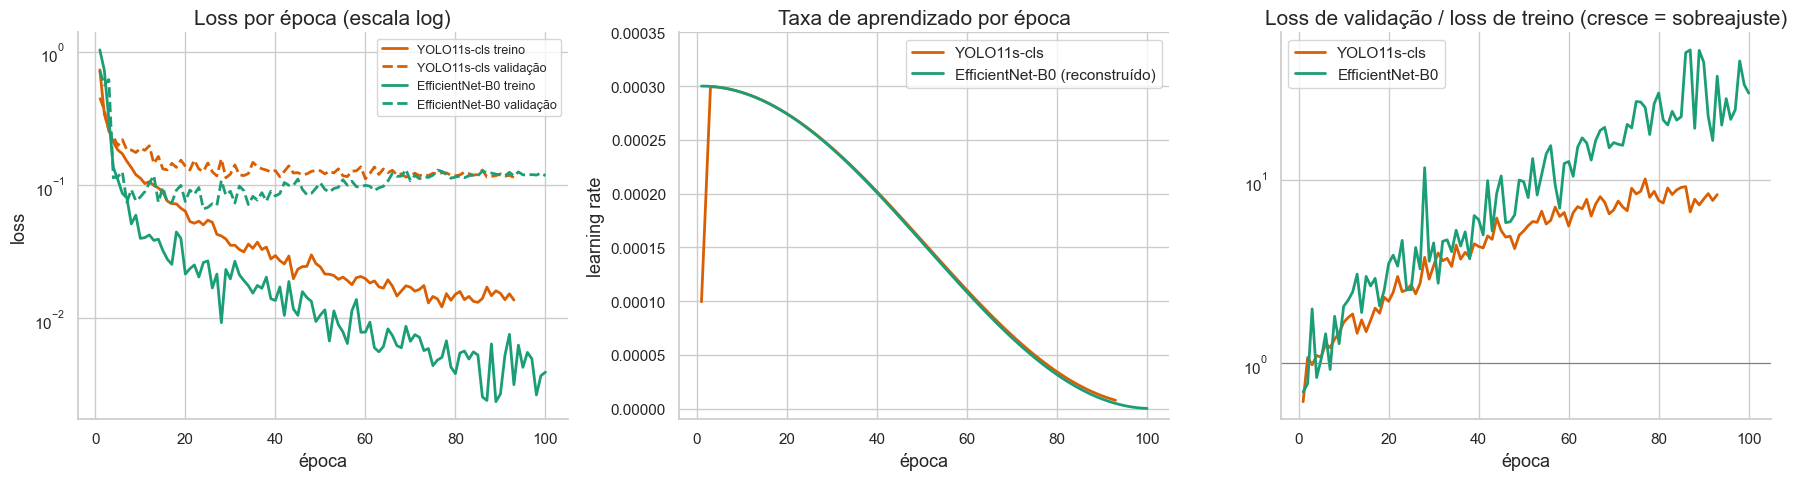

salvo: 06_treinamento_loss_lr.png


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for m, ep_, tl, vl, lr in ((NOME_Y, ey, hist_y["train/loss"].values, hist_y["val/loss"].values, hist_y["lr/pg0"].values), (NOME_C, ec, hist_c["loss_treino"].values, hist_c["loss_val"].values, hist_c["lr"].values)):
    ax[0].plot(ep_, tl, color=COR[m], lw=2, label=f"{m} treino"); ax[0].plot(ep_, vl, color=COR[m], lw=2, ls="--", label=f"{m} validação"); ax[1].plot(ep_, lr, color=COR[m], lw=2, label=m + (" (reconstruído)" if m == NOME_C else ""))
    ax[2].plot(ep_, vl / tl, color=COR[m], lw=2, label=m)
ax[0].set_yscale("log"); ax[0].set_title("Loss por época (escala log)"); ax[0].set_xlabel("época"); ax[0].set_ylabel("loss"); ax[0].legend(fontsize=9)
ax[1].set_ylim(-1e-5, 3.5e-4); ax[1].set_title("Taxa de aprendizado por época"); ax[1].set_xlabel("época"); ax[1].set_ylabel("learning rate"); ax[1].legend()
ax[2].set_yscale("log"); ax[2].axhline(1, color="gray", lw=.8); ax[2].set_title("Loss de validação / loss de treino (cresce = sobreajuste)"); ax[2].set_xlabel("época"); ax[2].legend(); plt.tight_layout()
tr_ = pd.DataFrame({NOME_Y: {"Épocas": len(ey), "Melhor época": int(ey[by]), "Acurácia de validação (melhor)": float(vy[by]), "Tempo de treino (min)": NK[NOME_Y]["tempo_treino_min"], "Loss de treino final": float(hist_y["train/loss"].iloc[-1])},
                    NOME_C: {"Épocas": len(ec), "Melhor época": int(ec[bc]), "Acurácia de validação (melhor)": float(vc[bc]), "Tempo de treino (min)": NK[NOME_C]["tempo_treino_min"], "Loss de treino final": float(hist_c["loss_treino"].iloc[-1])}}); reg_tab("06_resumo_treino", tr_, "Resumo do treinamento")
for m in MODELOS: NUM[f"tempo_treino_min_{m}"] = round(float(NK[m]["tempo_treino_min"]), 1); NUM[f"plato_inicio_{m}"] = NK[m]["plato_inicio"]; NUM[f"otimismo_selecao_pp_{m}"] = NK[m]["otimismo_selecao_pp"]
salvar("06_treinamento_loss_lr.png", "Loss e taxa de aprendizado dos dois treinos",
       "Loss de treino (linha cheia) e de validação (tracejada) de cada modelo, a taxa de aprendizado por época (YOLO: gravada; CNN: reconstruída pela fórmula do cosine) e a razão entre a loss de validação e a de treino.",
       "As escalas das losses diferem entre os frameworks (compare o formato, não o valor). Razão perto de 1 e estável indica pouco sobreajuste; razão crescente indica a validação se afastando do treino.",
       f"Os dois usam AdamW com taxa inicial de 3e-4 e decaimento cosseno; o YOLO tem warm-up nas 3 primeiras épocas. Tempo de treino: YOLO {NUM['tempo_treino_min_'+NOME_Y]/60:.1f} h (CPU) e CNN {NUM['tempo_treino_min_'+NOME_C]:.0f} min (hardware não registrado, portanto os tempos não são comparáveis). Início do platô de validação: época {NUM['plato_inicio_'+NOME_Y]} (YOLO) e {NUM['plato_inicio_'+NOME_C]} (CNN).")

## Figura 7 — Confusões e métricas por classe

,Modelo,Classe,Precisão,Recall,F1
0,YOLO11s-cls,glioma,0.9709,0.9824,0.9766
1,YOLO11s-cls,meningioma,0.9769,0.9602,0.9685
2,YOLO11s-cls,notumor,0.9747,0.9872,0.9809
3,YOLO11s-cls,pituitary,0.9944,0.9888,0.9916
4,EfficientNet-B0,glioma,0.9941,0.9941,0.9941
5,EfficientNet-B0,meningioma,0.9886,0.9830,0.9858
6,EfficientNet-B0,notumor,1.0000,0.9936,0.9968
7,EfficientNet-B0,pituitary,0.9834,0.9944,0.9889


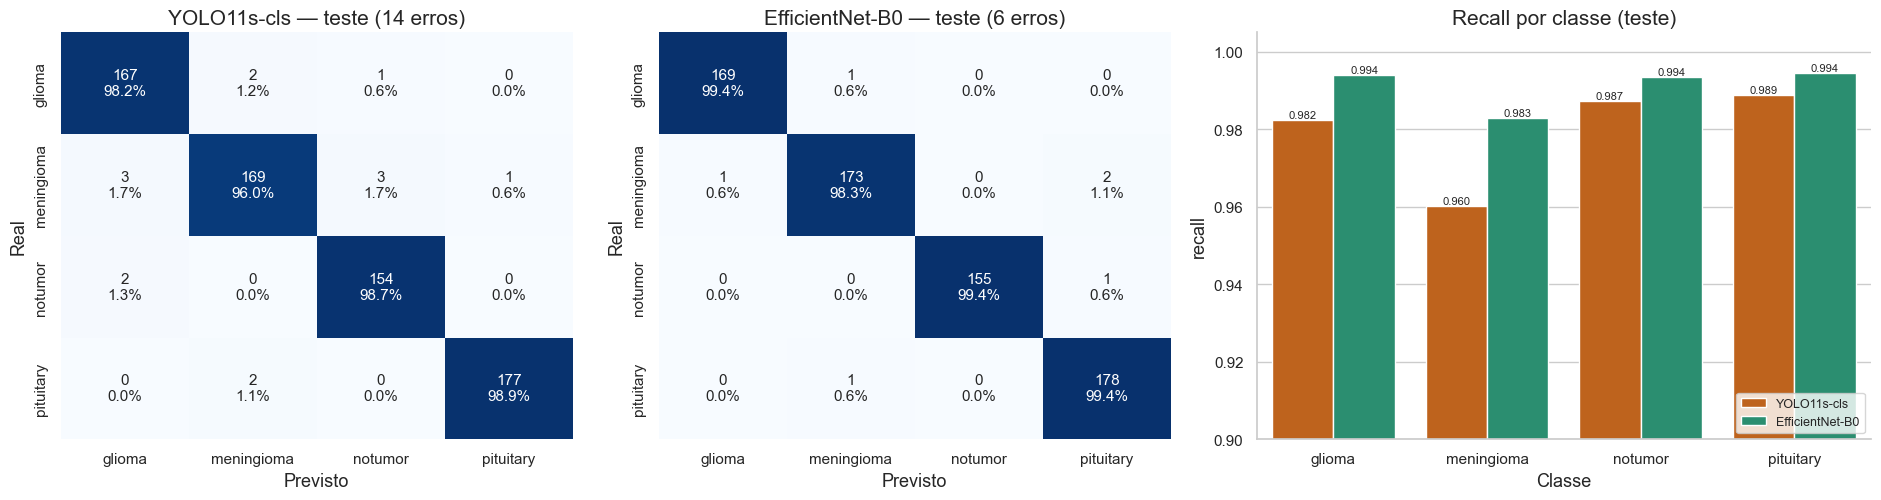

salvo: 07_confusao_e_por_classe.png


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.2), gridspec_kw={"width_ratios": [1, 1, 1.2]})
for a, m in zip(ax[:2], MODELOS):
    cm = confusion_matrix(Y["test"], PRED[m]["test"]); cn = cm / cm.sum(1, keepdims=True); lab = np.array([[f"{cm[i,j]}\n{100*cn[i,j]:.1f}%" for j in range(NC)] for i in range(NC)])
    sns.heatmap(cn, annot=lab, fmt="", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES, ax=a, cbar=False, annot_kws={"size": 11}); a.set_title(f"{m} — teste ({NUM['erros_teste_'+m]} erros)"); a.set_xlabel("Previsto"); a.set_ylabel("Real")
rows = [dict(Modelo=m, Classe=c, Precisão=precision_score(Y["test"], PRED[m]["test"], average=None)[i], Recall=recall_score(Y["test"], PRED[m]["test"], average=None)[i], F1=f1_score(Y["test"], PRED[m]["test"], average=None)[i]) for m in MODELOS for i, c in enumerate(CLASSES)]
PCL = pd.DataFrame(rows); d = PCL.melt(id_vars=["Modelo", "Classe"], var_name="Métrica", value_name="valor"); d = d[d["Métrica"] == "Recall"]; sns.barplot(data=d, x="Classe", y="valor", hue="Modelo", palette=COR, ax=ax[2]); ax[2].set_ylim(.9, 1.005); ax[2].set_title("Recall por classe (teste)"); ax[2].set_ylabel("recall"); ax[2].legend(loc="lower right", fontsize=9)
for c in ax[2].containers: ax[2].bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout(); reg_tab("07_por_classe_teste", PCL, "Precisão, recall e F1 por classe (teste)", index=False)
def pares(m):
    cm = confusion_matrix(Y["test"], PRED[m]["test"]).copy(); np.fill_diagonal(cm, 0); return sorted([(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(NC) for j in range(NC) if cm[i, j]], key=lambda t: -t[2])[:3]
for m in MODELOS: sub = PCL[PCL["Modelo"] == m]; NUM[f"menor_recall_{m}"] = round(float(sub["Recall"].min()), 4); NUM[f"classe_menor_recall_{m}"] = sub.loc[sub["Recall"].idxmin(), "Classe"]
py_, pc_ = pares(NOME_Y), pares(NOME_C)
salvar("07_confusao_e_por_classe.png", "Matrizes de confusão e recall por classe",
       "Matriz de confusão de cada modelo no teste (contagem e % da linha) e o recall de cada classe.",
       "A diagonal são os acertos; células fora da diagonal mostram qual classe é confundida com qual. Recall baixo em uma classe indica onde o modelo é mais fraco.",
       f"Confusões mais frequentes (real → previsto): {NOME_Y}: " + "; ".join(f"{a}→{b} ({n})" for a, b, n in py_) + f". {NOME_C}: " + "; ".join(f"{a}→{b} ({n})" for a, b, n in pc_) + f". Pior recall: {NOME_Y} {NUM['menor_recall_'+NOME_Y]:.3f} ({NUM['classe_menor_recall_'+NOME_Y]}) e {NOME_C} {NUM['menor_recall_'+NOME_C]:.3f} ({NUM['classe_menor_recall_'+NOME_C]}).")

## Figura 8 — Calibração e predição seletiva

,YOLO11s-cls,EfficientNet-B0
ECE,0.0050,0.0087
Brier,0.0324,0.0158
Confiança média nos acertos,0.9870,0.9984
Confiança média nos erros,0.7777,0.9102
"Cobertura mantendo ≥ 99,5%",0.8899,0.9927


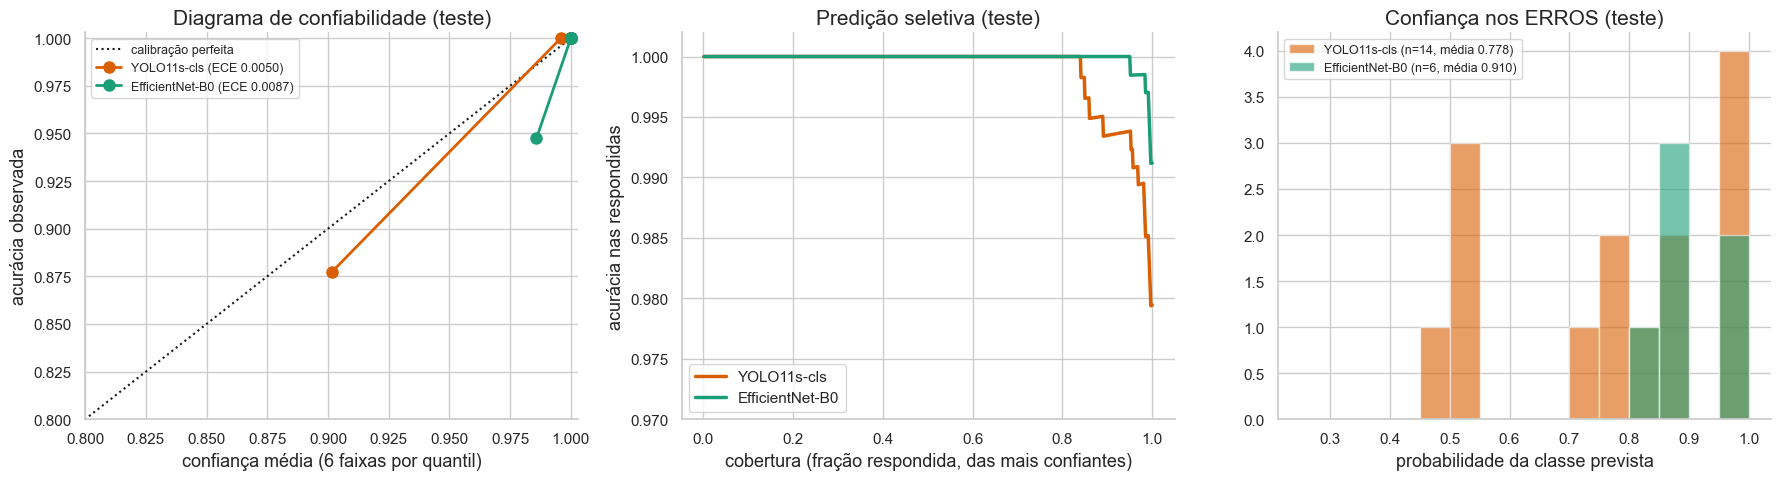

salvo: 08_calibracao_e_selecao.png


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5)); ax[0].plot([0, 1], [0, 1], "k:", label="calibração perfeita"); ECE = {}
for m in MODELOS:
    P = PROB[m]["test"]; conf, ok = P.max(1), PRED[m]["test"] == Y["test"]; gr_ = np.array_split(np.argsort(conf), 6); ECE[m] = ece(Y["test"], P)
    ax[0].plot([conf[g_].mean() for g_ in gr_], [ok[g_].mean() for g_ in gr_], "o-", color=COR[m], lw=2, ms=8, label=f"{m} (ECE {ECE[m]:.4f})")
    o = np.argsort(-conf); ax[1].plot(np.arange(1, len(o) + 1) / len(o), np.cumsum(ok[o]) / np.arange(1, len(o) + 1), color=COR[m], lw=2.5, label=m)
    v = conf[~ok]
    if len(v): ax[2].hist(v, bins=np.linspace(.25, 1, 16), alpha=.6, color=COR[m], label=f"{m} (n={len(v)}, média {v.mean():.3f})")
ax[0].set_xlim(.8, 1.003); ax[0].set_ylim(.8, 1.003); ax[0].set_xlabel("confiança média (6 faixas por quantil)"); ax[0].set_ylabel("acurácia observada"); ax[0].set_title("Diagrama de confiabilidade (teste)"); ax[0].legend(fontsize=9, loc="upper left")
ax[1].set_ylim(.97, 1.002); ax[1].set_xlabel("cobertura (fração respondida, das mais confiantes)"); ax[1].set_ylabel("acurácia nas respondidas"); ax[1].set_title("Predição seletiva (teste)"); ax[1].legend(loc="lower left")
ax[2].set_xlabel("probabilidade da classe prevista"); ax[2].set_title("Confiança nos ERROS (teste)"); ax[2].legend(fontsize=9); plt.tight_layout()
def cob(m, alvo):
    P = PROB[m]["test"]; conf, ok = P.max(1), PRED[m]["test"] == Y["test"]; o = np.argsort(-conf); a = np.cumsum(ok[o]) / np.arange(1, len(o) + 1); k = np.where(a >= alvo)[0]; return (k.max() + 1) / len(o) if len(k) else 0
CAL = pd.DataFrame({m: {"ECE": ECE[m], "Brier": brier(Y["test"], PROB[m]["test"]), "Confiança média nos acertos": PROB[m]["test"].max(1)[PRED[m]["test"] == Y["test"]].mean(), "Confiança média nos erros": PROB[m]["test"].max(1)[PRED[m]["test"] != Y["test"]].mean(), "Cobertura mantendo ≥ 99,5%": cob(m, .995)} for m in MODELOS}); reg_tab("08_calibracao", CAL, "Calibração e predição seletiva")
for m in MODELOS: NUM[f"ece_{m}"] = round(ECE[m], 4); NUM[f"cobertura_995_{m}"] = round(cob(m, .995), 3); NUM[f"conf_erros_{m}"] = round(float(CAL.loc["Confiança média nos erros", m]), 3)
salvar("08_calibracao_e_selecao.png", "Calibração e predição seletiva dos dois modelos",
       "Confiança declarada × acurácia observada (6 faixas com o mesmo número de imagens), acurácia ao responder só as imagens mais confiantes e a confiança nos erros de cada modelo.",
       "Pontos sobre a diagonal indicam confiança honesta. Erros com confiança baixa mostram que o modelo 'sabe quando duvida'; a curva alta à esquerda mostra que as previsões mais confiantes são mais confiáveis.",
       f"ECE no teste: {NOME_Y} {ECE[NOME_Y]:.4f} e {NOME_C} {ECE[NOME_C]:.4f} (ambos bem abaixo de 0,03). Confiança média nos erros: {NUM['conf_erros_'+NOME_Y]:.2f} (YOLO) e {NUM['conf_erros_'+NOME_C]:.2f} (CNN). A cobertura que mantém ≥ 99,5% de acurácia é {100*NUM['cobertura_995_'+NOME_Y]:.0f}% no YOLO e {100*NUM['cobertura_995_'+NOME_C]:.0f}% na CNN.")

## Figura 9 — Visão clínica (tumor × sem tumor)

,YOLO11s-cls,EfficientNet-B0
AUC binária,0.9999,0.9999
"Sensibilidade (corte 0,50)",0.9924,1.0000
"Especificidade (corte 0,50)",0.9872,0.9936
"Falsos negativos (0,50)",4.0000,0.0000
"Falsos positivos (0,50)",2.0000,1.0000
"Corte da validação (sens ≥ 99,5%)",0.0726,0.6952
Sensibilidade (corte da validação),0.9981,1.0000
Especificidade (corte da validação),0.9808,0.9936
Falsos negativos (corte da validação),1.0000,0.0000
Falsos positivos (corte da validação),3.0000,1.0000


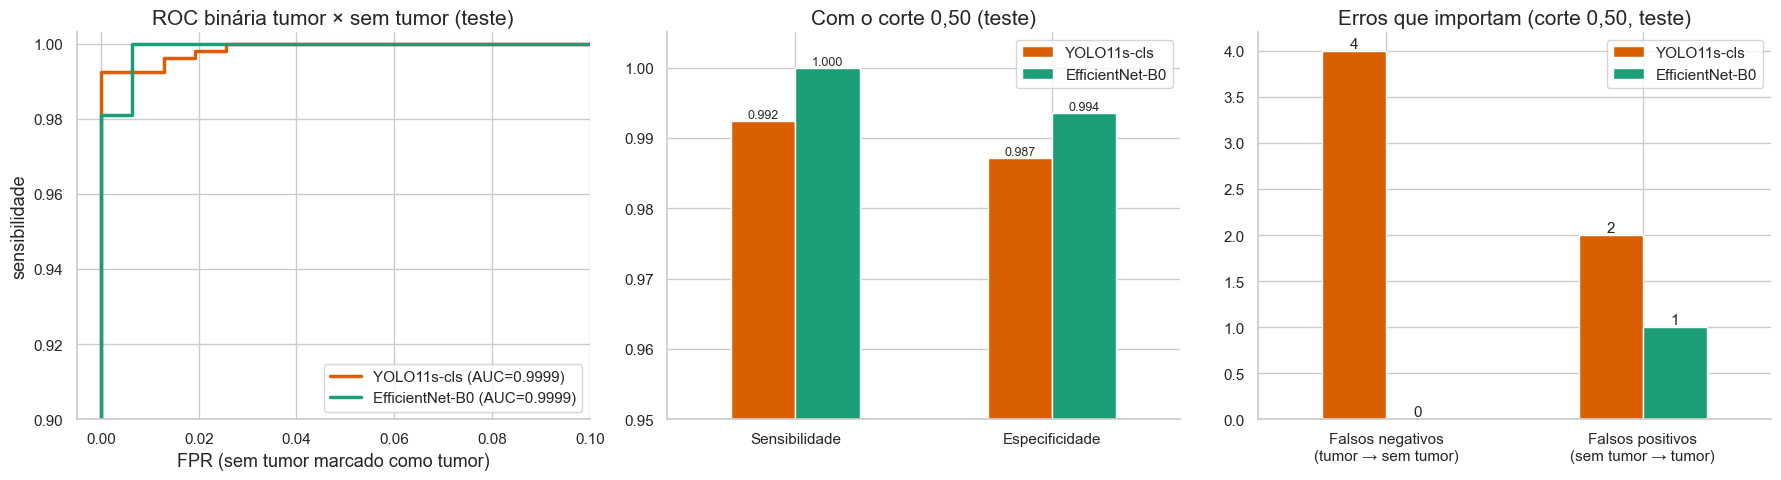

salvo: 09_visao_clinica.png


In [12]:
yb = {s: (Y[s] != i_nt).astype(int) for s in SV}; sc = {m: {s: 1 - PROB[m][s][:, i_nt] for s in SV} for m in MODELOS}; gr = np.linspace(.0005, .9995, 500); CL = {}
def se_es(m, s, t): pr = sc[m][s] >= t; tp = ((yb[s] == 1) & pr).sum(); fn = ((yb[s] == 1) & ~pr).sum(); tn = ((yb[s] == 0) & ~pr).sum(); fp = ((yb[s] == 0) & pr).sum(); return tp / (tp + fn), tn / (tn + fp), int(fn), int(fp)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for m in MODELOS:
    f, t_, _ = roc_curve(yb["test"], sc[m]["test"]); ax[0].plot(f, t_, color=COR[m], lw=2.5, label=f"{m} (AUC={roc_auc_score(yb['test'], sc[m]['test']):.4f})")
    sv = np.array([se_es(m, "val", t)[0] for t in gr]); okk = np.where(sv >= .995)[0]; ts = float(gr[okk.max()]) if len(okk) else .5; d50 = se_es(m, "test", .5); dsel = se_es(m, "test", ts)
    CL[m] = dict(auc=roc_auc_score(yb["test"], sc[m]["test"]), s50=d50[0], e50=d50[1], fn50=d50[2], fp50=d50[3], ts=ts, ssel=dsel[0], esel=dsel[1], fnsel=dsel[2], fpsel=dsel[3])
ax[0].set_xlim(-.005, .1); ax[0].set_ylim(.9, 1.003); ax[0].set_xlabel("FPR (sem tumor marcado como tumor)"); ax[0].set_ylabel("sensibilidade"); ax[0].set_title("ROC binária tumor × sem tumor (teste)"); ax[0].legend(loc="lower right")
dd = pd.DataFrame({m: [CL[m]["s50"], CL[m]["e50"]] for m in MODELOS}, index=["Sensibilidade", "Especificidade"]); dd.plot.bar(ax=ax[1], rot=0, color=[COR[m] for m in MODELOS]); ax[1].set_ylim(.95, 1.005); ax[1].set_title("Com o corte 0,50 (teste)")
for c in ax[1].containers: ax[1].bar_label(c, fmt="%.3f", fontsize=9)
d2 = pd.DataFrame({m: [CL[m]["fn50"], CL[m]["fp50"]] for m in MODELOS}, index=["Falsos negativos\n(tumor → sem tumor)", "Falsos positivos\n(sem tumor → tumor)"]); d2.plot.bar(ax=ax[2], rot=0, color=[COR[m] for m in MODELOS]); ax[2].set_title("Erros que importam (corte 0,50, teste)")
for c in ax[2].containers: ax[2].bar_label(c, fontsize=11)
plt.tight_layout(); reg_tab("09_visao_clinica", pd.DataFrame(CL).rename(index={"auc": "AUC binária", "s50": "Sensibilidade (corte 0,50)", "e50": "Especificidade (corte 0,50)", "fn50": "Falsos negativos (0,50)", "fp50": "Falsos positivos (0,50)", "ts": "Corte da validação (sens ≥ 99,5%)", "ssel": "Sensibilidade (corte da validação)", "esel": "Especificidade (corte da validação)", "fnsel": "Falsos negativos (corte da validação)", "fpsel": "Falsos positivos (corte da validação)"}), "Visão clínica por modelo")
for m in MODELOS:
    for k, v_ in CL[m].items(): NUM[f"clin_{k}_{m}"] = round(float(v_), 4) if isinstance(v_, float) else v_
pl = lambda n, a, b: f"{n} {a if n == 1 else b}"
salvar("09_visao_clinica.png", "Visão clínica: qual modelo deixa passar menos tumores?",
       "Glioma, meningioma e pituitary agrupados contra 'notumor': ROC binária, sensibilidade e especificidade com o corte padrão 0,50 e a contagem de falsos negativos e positivos de cada modelo no teste.",
       "O erro mais grave é o falso negativo (tumor classificado como normal). Sensibilidade perto de 100% e poucos falsos negativos são desejáveis.",
       f"Com o corte 0,50 no teste: {NOME_C} sensibilidade {CL[NOME_C]['s50']:.3f} ({pl(CL[NOME_C]['fn50'], 'falso negativo', 'falsos negativos')}), especificidade {CL[NOME_C]['e50']:.3f}; {NOME_Y} sensibilidade {CL[NOME_Y]['s50']:.3f} ({pl(CL[NOME_Y]['fn50'], 'falso negativo', 'falsos negativos')}), especificidade {CL[NOME_Y]['e50']:.3f}. Escolhendo na validação o corte para sensibilidade ≥ 99,5% ({CL[NOME_C]['ts']:.2f} na CNN e {CL[NOME_Y]['ts']:.2f} no YOLO), a sensibilidade no teste é {CL[NOME_C]['ssel']:.3f} e {CL[NOME_Y]['ssel']:.3f}.")

## Figura 10 — A diferença entre os modelos é real? (estatística pareada)
Com ~700 imagens, 1–2 erros mudam a 2ª casa decimal. Usamos o **bootstrap pareado** (diferença de acurácia CNN − YOLO com as mesmas reamostragens), o **teste de McNemar exato** (compara os erros nas mesmas imagens), a **estabilidade por 50 dobras estratificadas** do teste (5 dobras × 10 repetições; mede a oscilação da amostra de teste, não a do treino) e um **ensemble** (média das probabilidades).

,Teste,Validação
Só a CNN acerta,11.0000,26.0
Só o YOLO acerta,3.0000,2.0
Ambos erram,3.0000,
Ambos acertam,664.0000,
McNemar p (exato),0.0574,0.000003
Kappa entre modelos,0.9706,
Acurácia do ensemble,0.9927,
Dif. de acurácia CNN−YOLO (p.p.),1.1736,
IC 95% inf (p.p.),0.1468,
IC 95% sup (p.p.),2.3495,


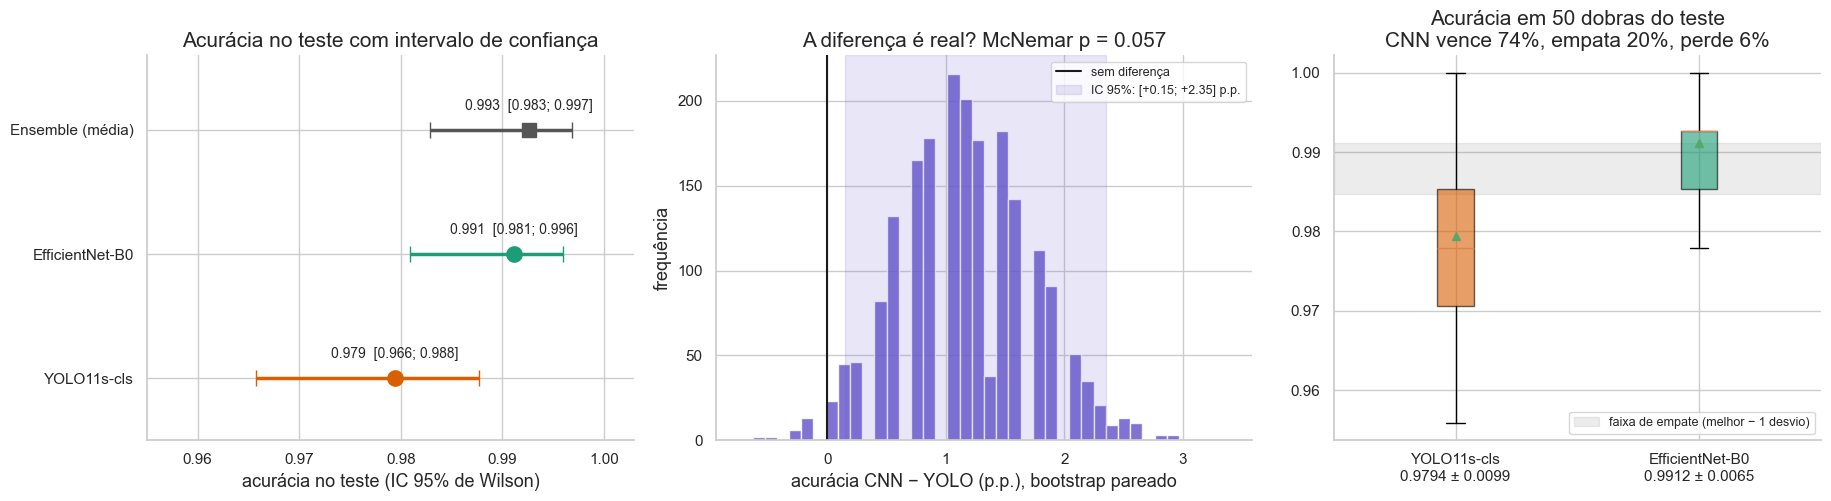

salvo: 10_estatistica_pareada.png


In [13]:
rng = np.random.default_rng(SEED); N = len(Y["test"]); dif, dif_f1, dif_ll = [], [], []
for _ in range(N_BOOT):
    i = rng.integers(0, N, N); dif.append((PRED[NOME_C]["test"][i] == Y["test"][i]).mean() - (PRED[NOME_Y]["test"][i] == Y["test"][i]).mean())
    dif_ll.append(perda(Y["test"][i], PROB[NOME_C]["test"][i]).mean() - perda(Y["test"][i], PROB[NOME_Y]["test"][i]).mean())
dif, dif_ll = np.array(dif), np.array(dif_ll); ic = lambda v: np.percentile(v, [2.5, 97.5])
oy, oc = PRED[NOME_Y]["test"] == Y["test"], PRED[NOME_C]["test"] == Y["test"]; so_c, so_y, ambos, nenhum = int((~oy & oc).sum()), int((oy & ~oc).sum()), int((~oy & ~oc).sum()), int((oy & oc).sum()); p_mc = binomtest(min(so_c, so_y), so_c + so_y, .5).pvalue
ov, ocv = PRED[NOME_Y]["val"] == Y["val"], PRED[NOME_C]["val"] == Y["val"]; sc_v, sy_v = int((~ov & ocv).sum()), int((ov & ~ocv).sum()); p_mcv = binomtest(min(sc_v, sy_v), sc_v + sy_v, .5).pvalue
ens = ((PROB[NOME_Y]["test"] + PROB[NOME_C]["test"]) / 2); acc_ens = accuracy_score(Y["test"], ens.argmax(1)); kap = cohen_kappa_score(PRED[NOME_Y]["test"], PRED[NOME_C]["test"])
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED); FA = {m: [] for m in MODELOS}
for _, idx in rskf.split(np.zeros(N), Y["test"]):
    for m in MODELOS: FA[m].append((PRED[m]["test"][idx] == Y["test"][idx]).mean())
FA = {m: np.array(v) for m, v in FA.items()}; dfold = FA[NOME_C] - FA[NOME_Y]; vit, emp, der = float((dfold > 0).mean()), float((dfold == 0).mean()), float((dfold < 0).mean())
fig, ax = plt.subplots(1, 3, figsize=(18.5, 5.2), gridspec_kw={"width_ratios": [1, 1.1, 1]})
for k, m in enumerate(MODELOS): a_ = acc(m, "test"); lo, hi = wilson(int((PRED[m]["test"] == Y["test"]).sum()), N); ax[0].errorbar(a_, k, xerr=[[a_ - lo], [hi - a_]], fmt="o", color=COR[m], capsize=6, ms=11, lw=2.5); ax[0].text(a_, k + .16, f"{a_:.3f}  [{lo:.3f}; {hi:.3f}]", ha="center", fontsize=10)
lo_e, hi_e = wilson(int((ens.argmax(1) == Y["test"]).sum()), N); ax[0].errorbar(acc_ens, 2, xerr=[[acc_ens - lo_e], [hi_e - acc_ens]], fmt="s", color="#555", capsize=6, ms=10, lw=2.5); ax[0].text(acc_ens, 2.16, f"{acc_ens:.3f}  [{lo_e:.3f}; {hi_e:.3f}]", ha="center", fontsize=10)
ax[0].set_yticks([0, 1, 2]); ax[0].set_yticklabels(MODELOS + ["Ensemble (média)"]); ax[0].set_ylim(-.5, 2.6); ax[0].set_xlim(.955, 1.003); ax[0].set_xlabel("acurácia no teste (IC 95% de Wilson)"); ax[0].set_title("Acurácia no teste com intervalo de confiança")
ax[1].hist(100 * dif, bins=40, color="#6a5acd", alpha=.85); ax[1].axvline(0, color="k", lw=1.5, label="sem diferença"); ax[1].axvspan(100 * ic(dif)[0], 100 * ic(dif)[1], color="#6a5acd", alpha=.15, label=f"IC 95%: [{100*ic(dif)[0]:+.2f}; {100*ic(dif)[1]:+.2f}] p.p.")
ax[1].set_xlabel("acurácia CNN − YOLO (p.p.), bootstrap pareado"); ax[1].set_ylabel("frequência"); ax[1].set_title(f"A diferença é real? McNemar p = {p_mc:.3f}"); ax[1].legend(fontsize=9)
bp = ax[2].boxplot([FA[m] for m in MODELOS], labels=[f"{m}\n{FA[m].mean():.4f} ± {FA[m].std(ddof=1):.4f}" for m in MODELOS], patch_artist=True, showmeans=True)
for p_, m in zip(bp["boxes"], MODELOS): p_.set_facecolor(COR[m]); p_.set_alpha(.6)
lider = max(MODELOS, key=lambda m: FA[m].mean()); ax[2].axhspan(FA[lider].mean() - FA[lider].std(ddof=1), FA[lider].mean(), color="gray", alpha=.15, label="faixa de empate (melhor − 1 desvio)"); ax[2].set_title(f"Acurácia em 50 dobras do teste\nCNN vence {100*vit:.0f}%, empata {100*emp:.0f}%, perde {100*der:.0f}%"); ax[2].legend(fontsize=9, loc="lower right"); plt.tight_layout()
outro = [m for m in MODELOS if m != lider][0]; fora = FA[outro].mean() < FA[lider].mean() - FA[lider].std(ddof=1)
reg_tab("10_pareada", pd.DataFrame({"Teste": {"Só a CNN acerta": so_c, "Só o YOLO acerta": so_y, "Ambos erram": ambos, "Ambos acertam": nenhum, "McNemar p (exato)": p_mc, "Kappa entre modelos": kap, "Acurácia do ensemble": acc_ens, "Dif. de acurácia CNN−YOLO (p.p.)": 100 * dif.mean(), "IC 95% inf (p.p.)": 100 * ic(dif)[0], "IC 95% sup (p.p.)": 100 * ic(dif)[1]}, "Validação": {"Só a CNN acerta": sc_v, "Só o YOLO acerta": sy_v, "McNemar p (exato)": p_mcv}}).fillna(""), "Comparação pareada")
NUM.update(so_cnn_acerta=so_c, so_yolo_acerta=so_y, ambos_erram=ambos, mcnemar_p_teste=round(p_mc, 4), mcnemar_p_val=float(p_mcv), kappa_entre_modelos=round(kap, 4), acc_ensemble=round(acc_ens, 4), dif_acc_pp=round(100 * dif.mean(), 2), ic_dif_inf_pp=round(100 * ic(dif)[0], 2), ic_dif_sup_pp=round(100 * ic(dif)[1], 2),
           dobras_cnn_vence_pct=round(100 * vit, 1), dobras_empate_pct=round(100 * emp, 1), dobras_yolo_vence_pct=round(100 * der, 1), dobras_fora_faixa_empate=bool(fora), dif_logloss=round(float(dif_ll.mean()), 4), ic_dif_logloss_inf=round(float(ic(dif_ll)[0]), 4), ic_dif_logloss_sup=round(float(ic(dif_ll)[1]), 4))
for m in MODELOS: NUM[f"dobras_media_{m}"] = round(FA[m].mean(), 4); NUM[f"dobras_desvio_{m}"] = round(FA[m].std(ddof=1), 4)
veredito = "estatisticamente significativa a 5%" if p_mc < .05 else ("limítrofe: o IC do bootstrap exclui zero por pouco, mas o McNemar não é significativo a 5%" if (ic(dif)[0] > 0 or ic(dif)[1] < 0) else "não significativa a 5%"); NUM["veredito_diferenca"] = veredito
salvar("10_estatistica_pareada.png", "A diferença entre os modelos é real? Bootstrap pareado, McNemar e dobras",
       "Esquerda: acurácia no teste com intervalo de confiança (e a do ensemble). Centro: distribuição bootstrap da diferença CNN − YOLO e o p do McNemar. Direita: acurácia em 50 dobras estratificadas do teste, com a faixa de empate do líder (melhor − 1 desvio).",
       "Intervalos que se sobrepõem podem ser ruído. Se o IC da diferença exclui zero e p < 0,05, a diferença é significativa. Se o segundo colocado está dentro da faixa de empate do primeiro, é empate técnico. As dobras medem a oscilação da amostra de teste, não a variância entre treinos, e não são independentes.",
       f"Diferença CNN − YOLO = {100*dif.mean():+.2f} p.p. (IC 95% [{100*ic(dif)[0]:+.2f}; {100*ic(dif)[1]:+.2f}]); McNemar no teste p = {p_mc:.3f} ({so_c} imagens só a CNN acerta × {so_y} só o YOLO) → {veredito}. Na validação (1379 imagens): {sc_v} × {sy_v}, p = {p_mcv:.2g}. Em 50 dobras: {NOME_C} {FA[NOME_C].mean():.4f} ± {FA[NOME_C].std(ddof=1):.4f} e {NOME_Y} {FA[NOME_Y].mean():.4f} ± {FA[NOME_Y].std(ddof=1):.4f}; {outro} fica {'fora' if fora else 'dentro'} da faixa de empate de {lider}. Kappa entre os modelos {kap:.3f}; ensemble {pp(acc_ens)}.")

## Figura 11 — Robustez comparada (resultados lidos das pastas dos modelos)

,YOLO11s-cls,EfficientNet-B0
index,,
original,0.9750,0.9833
ruído gaussiano σ=10,0.7667,0.2583
ruído gaussiano σ=25,0.4000,0.2000
desfoque (raio 2),0.6667,0.5750
desfoque (raio 4),0.2500,0.4417
brilho −30%,0.9833,0.9833
brilho +30%,0.9667,0.9833
contraste −40%,0.9833,0.9833
JPEG q=20,0.5833,0.9833


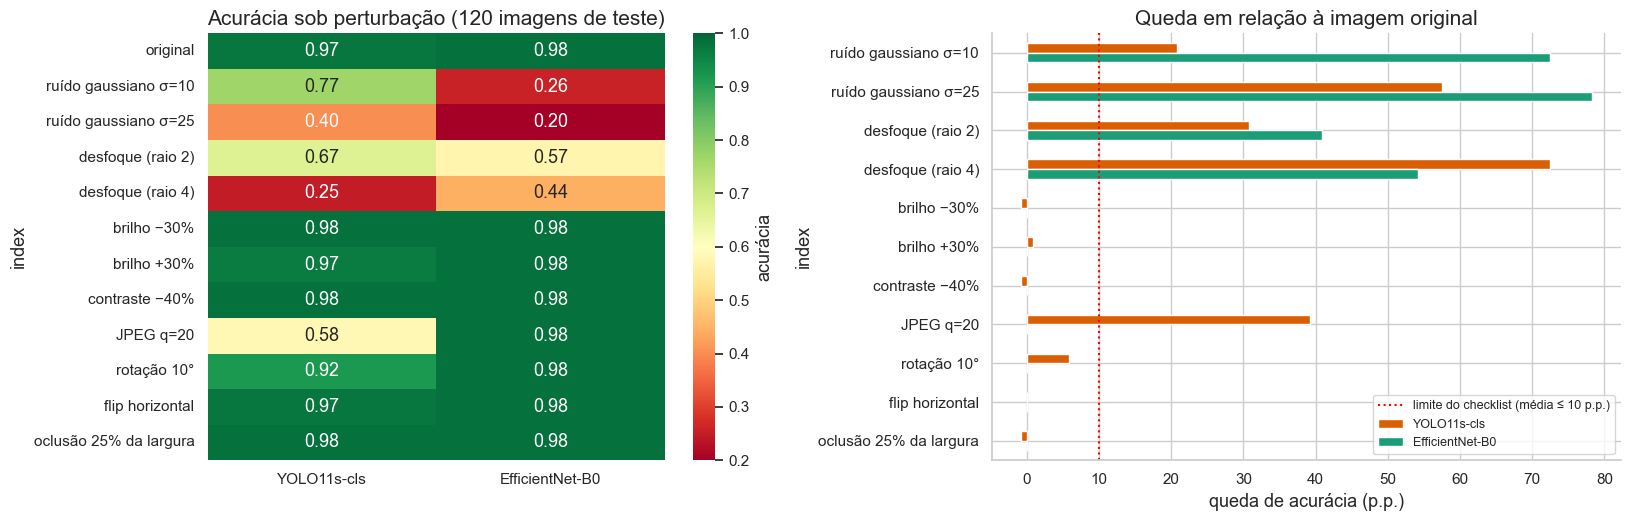

salvo: 11_robustez_comparada.png


In [14]:
RB = pd.DataFrame({m: pd.read_csv(PAST[m] / "tabelas" / "12_robustez.csv", index_col=0)["Acurácia"] for m in MODELOS}); RB = RB.loc[["original"] + [i for i in RB.index if i != "original"]]
drop = RB.loc["original"] - RB.drop(index="original"); fig, ax = plt.subplots(1, 2, figsize=(16.5, 5.4), gridspec_kw={"width_ratios": [1, 1.1]})
sns.heatmap(RB, annot=True, fmt=".2f", cmap="RdYlGn", vmin=.2, vmax=1, ax=ax[0], cbar_kws={"label": "acurácia"}); ax[0].set_title("Acurácia sob perturbação (120 imagens de teste)")
(100 * drop).plot.barh(ax=ax[1], color=[COR[m] for m in MODELOS]); ax[1].axvline(10, color="red", ls=":", label="limite do checklist (média ≤ 10 p.p.)"); ax[1].invert_yaxis(); ax[1].set_xlabel("queda de acurácia (p.p.)"); ax[1].set_title("Queda em relação à imagem original"); ax[1].legend(fontsize=9, loc="lower right"); plt.tight_layout()
qm = drop.mean(); reg_tab("11_robustez", RB, "Acurácia sob perturbação")
for m in MODELOS: NUM[f"queda_media_pp_{m}"] = round(100 * qm[m], 1); NUM[f"pior_perturbacao_{m}"] = drop[m].idxmax(); NUM[f"queda_pior_pp_{m}"] = round(100 * drop[m].max(), 1)
jp = drop.loc["JPEG q=20"]; NUM["jpeg_queda_YOLO"] = round(100 * jp[NOME_Y], 1); NUM["jpeg_queda_CNN"] = round(100 * jp[NOME_C], 1)
salvar("11_robustez_comparada.png", "Robustez a perturbações sintéticas nos dois modelos",
       "Acurácia dos dois modelos, nas mesmas imagens e com as mesmas perturbações (ruído gaussiano, desfoque, brilho, contraste, JPEG, rotação, espelhamento, oclusão), e a queda em relação à imagem original. Resultados calculados nos notebooks de cada modelo.",
       "Verde mantém a acurácia, vermelho falha. Quanto menor a queda, mais robusto. Perturbações sintéticas indicam sensibilidade e não substituem validação em outro scanner ou hospital.",
       f"Queda média: {NOME_Y} {NUM['queda_media_pp_'+NOME_Y]:.1f} p.p. e {NOME_C} {NUM['queda_media_pp_'+NOME_C]:.1f} p.p. (os dois acima do limite de 10 p.p.). Pior caso: {NOME_Y} {NUM['pior_perturbacao_'+NOME_Y]} (−{NUM['queda_pior_pp_'+NOME_Y]:.0f} p.p.); {NOME_C} {NUM['pior_perturbacao_'+NOME_C]} (−{NUM['queda_pior_pp_'+NOME_C]:.0f} p.p.). A compressão JPEG q=20 afeta o YOLO (−{NUM['jpeg_queda_YOLO']:.0f} p.p.) mas pouco a CNN (−{NUM['jpeg_queda_CNN']:.0f} p.p.); ruído e desfoque forte derrubam os dois. Brilho, contraste, espelhamento e oclusão não alteram os resultados.")

## Figuras 12 e 13 — Mapas de calor (Grad-CAM): mantidos exatamente como estão
Os dois painéis aprovados são **copiados sem alteração** (conferência por hash) da pasta arquivada. Cada linha mostra a imagem original, o mapa de calor da EfficientNet-B0 e o do YOLO11s-cls. Vermelho/amarelo = região mais importante para a decisão.

preservado: 12_gradcam_acertos.png 53d72fd552bd6fe0


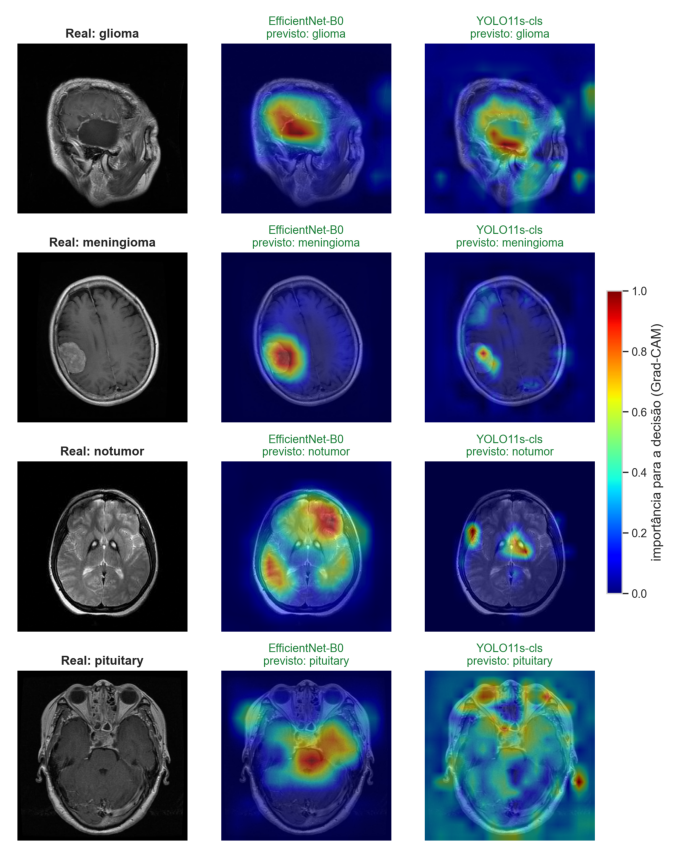

preservado: 13_gradcam_erros.png 215df12b53c548e8


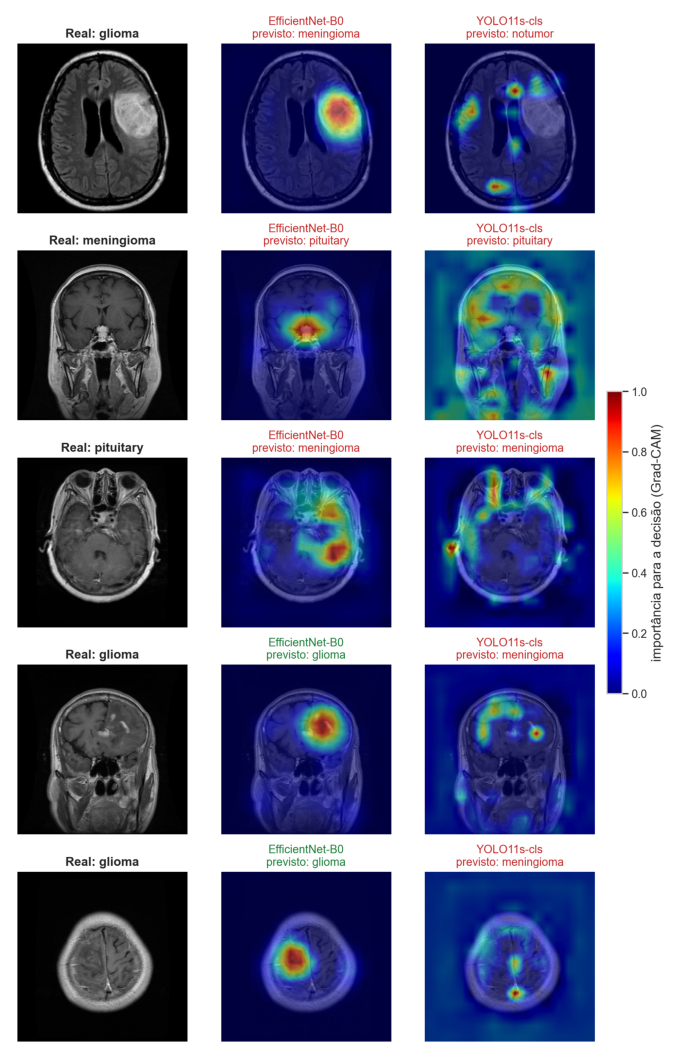

In [15]:
leg_ant = {l["arquivo"]: l for l in json.loads((V / "_anteriores" / "Kit_Apresentacao" / "legendas.json").read_text(encoding="utf-8"))}
for nome in ("12_gradcam_acertos.png", "13_gradcam_erros.png"):
    src, dst = HEAT / nome, FIG / nome
    if not src.exists() and not dst.exists(): raise FileNotFoundError(f"Imagem de mapa de calor não encontrada: {src}")
    if src.exists() and (not dst.exists() or hashlib.sha256(src.read_bytes()).hexdigest() != hashlib.sha256(dst.read_bytes()).hexdigest()): shutil.copy2(src, dst)
    if src.exists(): assert hashlib.sha256(src.read_bytes()).hexdigest() == hashlib.sha256(dst.read_bytes()).hexdigest(), "cópia diferente da original"
    l = leg_ant[nome]; LEG.append(dict(arquivo=nome, titulo=l["titulo"], mostra=l["mostra"], ler=l["ler"], resultado=l["resultado"])); print("preservado:", nome, hashlib.sha256(dst.read_bytes()).hexdigest()[:16])
    plt.figure(figsize=(7, 7 * Image.open(dst).size[1] / Image.open(dst).size[0])); plt.imshow(Image.open(dst)); plt.axis("off"); plt.tight_layout(); plt.show()

## Figura 14 — Erros: quem erra onde

,Arquivo,Real,YOLO previu,Conf. YOLO,CNN previu,Conf. CNN,Quem errou
0,Te-gl_62_jpg.rf.e5510a0f35d1fd15d06d9a14cacfa3...,glioma,notumor,0.7588,meningioma,0.9877,ambos
1,Tr-me_964_jpg.rf.6d728af1f74ceef073eb6acf88f7c...,meningioma,pituitary,0.8864,pituitary,0.8955,ambos
2,Tr-pi_1255_jpg.rf.4a24eef12abfbc89962f61594be4...,pituitary,meningioma,0.9895,meningioma,0.8831,ambos
3,Tr-aug-me_61_jpg.rf.382cf75f039a56fb94cc6df82e...,meningioma,meningioma,0.9669,pituitary,0.8512,só CNN
4,Tr-me_14_jpg.rf.a95e862ba6e125e89d602ae6f12479...,meningioma,meningioma,0.7904,glioma,0.8441,só CNN
5,Tr-no_907_jpg.rf.c9992476b360bb8a91dc09eceaa89...,notumor,notumor,0.9996,pituitary,0.9992,só CNN
6,Te-gl_91_jpg.rf.a96f97376f7996206becc54f4d2d22...,glioma,meningioma,0.7451,glioma,1.0000,só YOLO
7,Tr-gl_987_jpg.rf.be57035d7df07075c03d166f1106e...,glioma,meningioma,0.9835,glioma,0.8968,só YOLO
8,Tr-me_1059_jpg.rf.2c6d37e0f90724baf37c99095ad3...,meningioma,glioma,0.7556,meningioma,0.9969,só YOLO
9,Tr-me_1110_jpg.rf.bd2e6b251286a3e461ee93767aae...,meningioma,notumor,0.5488,meningioma,1.0000,só YOLO


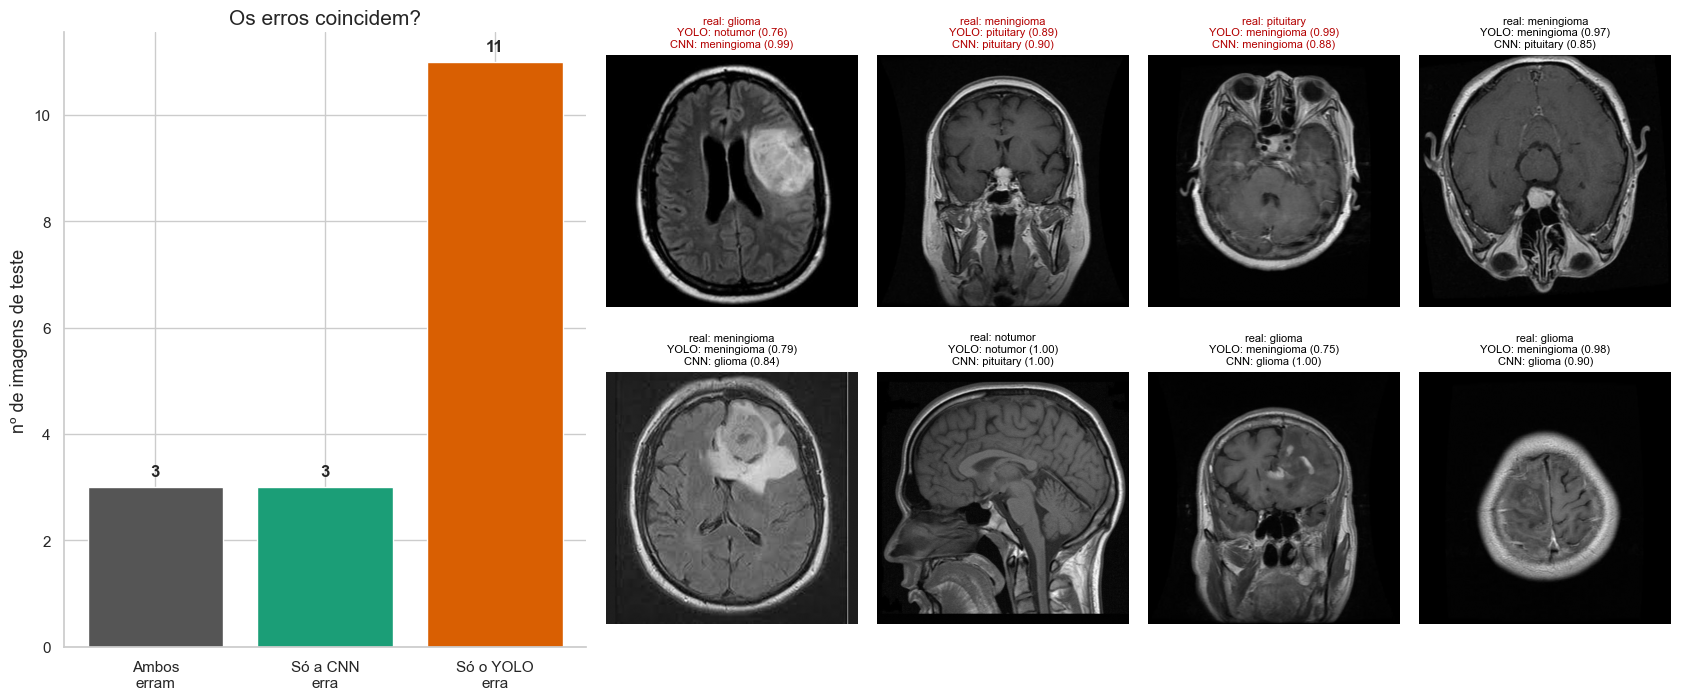

salvo: 14_erros_quem_erra_onde.png


In [16]:
e_y, e_c = ~oy, ~oc; idx = np.where(e_y | e_c)[0]
ER = pd.DataFrame([{"Arquivo": Path(CAM["test"][i]).name, "idx": int(i), "Real": CLASSES[Y["test"][i]], "YOLO previu": CLASSES[PRED[NOME_Y]["test"][i]], "Conf. YOLO": float(PROB[NOME_Y]["test"][i].max()), "CNN previu": CLASSES[PRED[NOME_C]["test"][i]], "Conf. CNN": float(PROB[NOME_C]["test"][i].max()),
                   "Quem errou": "ambos" if (e_y[i] and e_c[i]) else ("só YOLO" if e_y[i] else "só CNN")} for i in idx]); ordem_q = {"ambos": 0, "só CNN": 1, "só YOLO": 2}; ER = ER.sort_values(by=["Quem errou", "Real"], key=lambda s: s.map(ordem_q) if s.name == "Quem errou" else s).reset_index(drop=True)
reg_tab("14_erros", ER.drop(columns="idx").head(20), "Imagens de teste erradas por pelo menos um modelo (até 20)", index=False); ER.drop(columns="idx").to_csv(TAB / "14_erros_completo.csv", index=False, encoding="utf-8-sig")
fig = plt.figure(figsize=(17, 7.2)); gs = fig.add_gridspec(2, 6); axb = fig.add_subplot(gs[:, :2]); cnt = ER["Quem errou"].value_counts().reindex(["ambos", "só CNN", "só YOLO"]).fillna(0)
axb.bar(["Ambos\nerram", "Só a CNN\nerra", "Só o YOLO\nerra"], cnt.values, color=["#555", COR[NOME_C], COR[NOME_Y]]); axb.set_ylabel("nº de imagens de teste"); axb.set_title("Os erros coincidem?")
for i, v_ in enumerate(cnt.values): axb.text(i, v_ + .2, int(v_), ha="center", fontsize=12, fontweight="bold")
for k, (_, r) in enumerate(ER.head(8).iterrows()):
    a = fig.add_subplot(gs[k // 4, 2 + k % 4]); a.imshow(Image.open(CAM["test"][r["idx"]]).convert("L"), cmap="gray"); a.axis("off"); a.set_title(f"real: {r['Real']}\nYOLO: {r['YOLO previu']} ({r['Conf. YOLO']:.2f})\nCNN: {r['CNN previu']} ({r['Conf. CNN']:.2f})", fontsize=8, color="#b30000" if r["Quem errou"] == "ambos" else "black")
plt.tight_layout(); NUM.update(erros_ambos=int(cnt["ambos"]), erros_so_cnn=int(cnt["só CNN"]), erros_so_yolo=int(cnt["só YOLO"]), erros_uniao=int(len(ER)))
salvar("14_erros_quem_erra_onde.png", "Quem erra onde: sobreposição dos erros dos dois modelos",
       "Quantas imagens de teste só um dos modelos erra e quantas os dois erram, e as 8 primeiras imagens da lista (primeiro as que os dois erram), com a classe prevista e a confiança de cada modelo.",
       "Erros que não coincidem mostram que os modelos são complementares (um ensemble pode corrigir parte deles). Imagens que os dois erram são as mais difíceis ou ambíguas; títulos em vermelho indicam erro dos dois.",
       f"{len(ER)} imagens de teste têm erro de pelo menos um modelo: {int(cnt['ambos'])} dos dois, {int(cnt['só CNN'])} só da CNN e {int(cnt['só YOLO'])} só do YOLO. A baixa coincidência ({int(cnt['ambos'])} em comum) mostra erros em grande parte complementares; o ensemble por média das probabilidades alcança {pp(acc_ens)} no teste.")

## Figura 15 — Eficiência computacional (medida nos notebooks de cada modelo)

,YOLO11s-cls,EfficientNet-B0,Razão CNN/YOLO
Parâmetros (milhões),5.45,4.01,0.7358
GFLOPs por imagem,7.71,4.01,0.5201
Arquivo de pesos (MB),11.04,16.35,1.4810
"Latência mediana do modelo (ms, CPU)",76.70,136.30,1.7771
Tempo de treino (min),801.20,230.50,0.2877


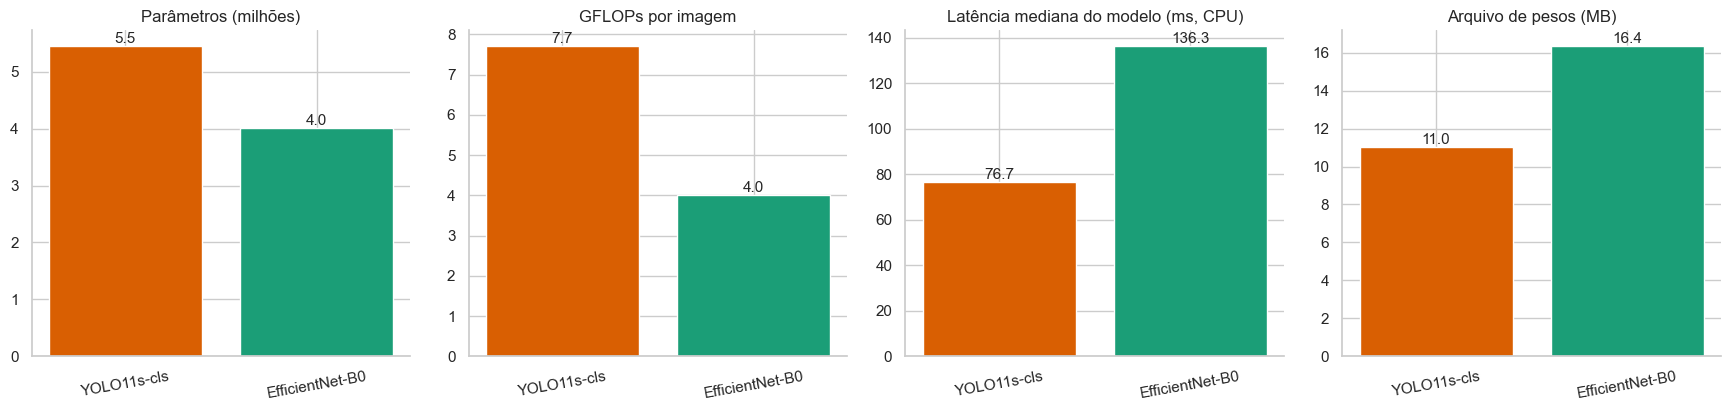

salvo: 15_eficiencia.png


In [17]:
EF = pd.DataFrame({m: {"Parâmetros (milhões)": NK[m]["parametros_M"], "GFLOPs por imagem": NK[m]["gflops"], "Arquivo de pesos (MB)": NK[m]["peso_mb"], "Latência mediana do modelo (ms, CPU)": NK[m]["latencia_mediana_ms"], "Tempo de treino (min)": NK[m]["tempo_treino_min"]} for m in MODELOS}); EF["Razão CNN/YOLO"] = EF[NOME_C] / EF[NOME_Y]; reg_tab("15_eficiencia", EF, "Custo computacional")
fig, ax = plt.subplots(1, 4, figsize=(17.5, 4.3))
for a, met in zip(ax, ["Parâmetros (milhões)", "GFLOPs por imagem", "Latência mediana do modelo (ms, CPU)", "Arquivo de pesos (MB)"]):
    v_ = [EF.loc[met, m] for m in MODELOS]; a.bar(MODELOS, v_, color=[COR[m] for m in MODELOS]); a.set_title(met, fontsize=12); a.tick_params(axis="x", labelrotation=10)
    for i, x_ in enumerate(v_): a.text(i, x_, f"{x_:.1f}", ha="center", va="bottom", fontsize=11)
plt.tight_layout()
for m in MODELOS: NUM[f"parametros_M_{m}"] = round(float(EF.loc["Parâmetros (milhões)", m]), 2); NUM[f"gflops_{m}"] = round(float(EF.loc["GFLOPs por imagem", m]), 2); NUM[f"latencia_ms_{m}"] = round(float(EF.loc["Latência mediana do modelo (ms, CPU)", m]), 1); NUM[f"peso_mb_{m}"] = round(float(EF.loc["Arquivo de pesos (MB)", m]), 2)
salvar("15_eficiencia.png", "Eficiência: tamanho, custo e velocidade dos dois modelos",
       "Número de parâmetros, custo de cálculo por imagem (GFLOPs), latência de inferência do modelo na CPU e tamanho do arquivo de pesos, medidos pelo notebook de cada modelo na mesma máquina.",
       "Menos parâmetros e GFLOPs indicam modelo mais leve, mas a latência real depende também de como a arquitetura usa a memória do hardware. Os pesos do YOLO são salvos em FP16 e os da CNN em FP32, então o tamanho em disco não é comparável diretamente.",
       f"A CNN é menor ({NUM['parametros_M_'+NOME_C]:.1f} M de parâmetros e {NUM['gflops_'+NOME_C]:.1f} GFLOPs, contra {NUM['parametros_M_'+NOME_Y]:.1f} M e {NUM['gflops_'+NOME_Y]:.1f}), porém mais lenta na CPU (latência mediana {NUM['latencia_ms_'+NOME_C]:.0f} ms contra {NUM['latencia_ms_'+NOME_Y]:.0f} ms). Medido em CPU; varia com o hardware.")

## Figura 16 — Checklist de aprovação lado a lado

,Critério,YOLO11s-cls,EfficientNet-B0
0,Acurácia no teste,ok,ok
1,Acurácia no teste limpo (sem quase-duplicatas),ok,ok
2,Menor recall entre as classes (teste),ok,ok
3,Sensibilidade para tumor (teste),ok,ok
4,AUC macro (teste),ok,ok
5,Log-loss (teste),ok,ok
6,Calibração: ECE (teste),ok,ok
7,Variância: gap treino − validação,ok,ok
8,Estabilidade: |gap validação − teste|,ok,ok
9,Divisão estratificada,ok,ok


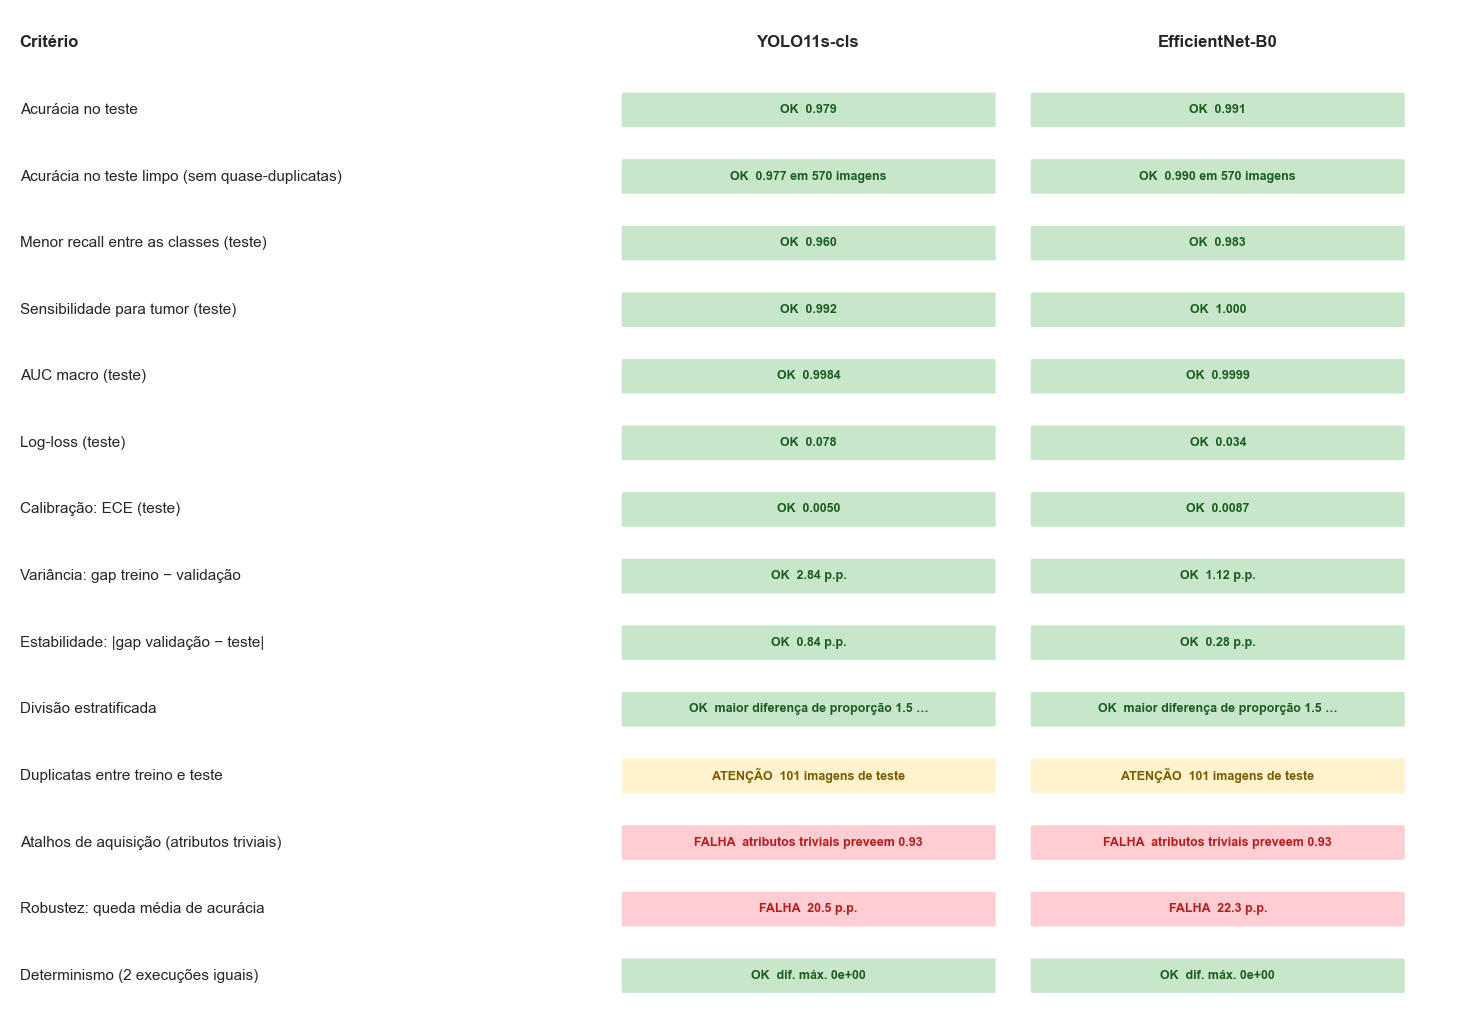

salvo: 16_checklist_lado_a_lado.png


In [18]:
crit = [c["item"] for c in CK[NOME_Y]]; sty = {"ok": ("#c8e6c9", "#1b5e20", "OK"), "atencao": ("#fff3cd", "#7a5b00", "ATENÇÃO"), "falha": ("#ffcdd2", "#b71c1c", "FALHA")}
fig, ax = plt.subplots(figsize=(15, 0.62 * len(crit) + 1.7)); ax.axis("off"); ax.set_xlim(0, 15); ax.set_ylim(0, len(crit) + 1)
ax.text(.1, len(crit) + .45, "Critério", fontweight="bold", fontsize=12); ax.text(8.2, len(crit) + .45, NOME_Y, fontweight="bold", ha="center", fontsize=12); ax.text(12.4, len(crit) + .45, NOME_C, fontweight="bold", ha="center", fontsize=12)
for r_, c in enumerate(crit):
    y_ = len(crit) - r_ - .5; ax.text(.1, y_, c, va="center", fontsize=11)
    for x_, m in ((8.2, NOME_Y), (12.4, NOME_C)):
        it = next(i for i in CK[m] if i["item"] == c); f_, fg, rot = sty[it["status"]]; ax.add_patch(mpatches.FancyBboxPatch((x_ - 1.9, y_ - .24), 3.8, .48, boxstyle="round,pad=0.02", fc=f_, ec="none")); ev = it["evidencia"].split(" (")[0]; ev = ev if len(ev) <= 34 else ev[:33] + "…"; ax.text(x_, y_, f"{rot}  {ev}", ha="center", va="center", fontsize=9, fontweight="bold", color=fg)
plt.tight_layout(); cont = {m: pd.Series([i["status"] for i in CK[m]]).value_counts().to_dict() for m in MODELOS}
for m in MODELOS: NUM[f"checklist_ok_{m}"] = int(cont[m].get("ok", 0)); NUM[f"checklist_atencao_{m}"] = int(cont[m].get("atencao", 0)); NUM[f"checklist_falha_{m}"] = int(cont[m].get("falha", 0))
NUM["checklist_total"] = len(crit); dif_ck = [c for c in crit if next(i for i in CK[NOME_Y] if i["item"] == c)["status"] != next(i for i in CK[NOME_C] if i["item"] == c)["status"]]
reg_tab("16_checklist", pd.DataFrame({"Critério": crit, NOME_Y: [next(i for i in CK[NOME_Y] if i["item"] == c)["status"] for c in crit], NOME_C: [next(i for i in CK[NOME_C] if i["item"] == c)["status"] for c in crit]}), "Status do checklist por modelo", index=False)
salvar("16_checklist_lado_a_lado.png", "Checklist de aprovação dos dois modelos",
       "Os 14 critérios de aprovação (desempenho, generalização, calibração, integridade dos dados, atalhos, robustez, reprodutibilidade) com o status de cada modelo e o valor medido.",
       "OK atende; ATENÇÃO vale registrar; FALHA deve ser investigada. Os critérios e metas são os mesmos dos notebooks de cada modelo (metas do grupo, não padrões clínicos).",
       f"{NOME_C}: {NUM['checklist_ok_'+NOME_C]} OK, {NUM['checklist_atencao_'+NOME_C]} atenção, {NUM['checklist_falha_'+NOME_C]} falhas. {NOME_Y}: {NUM['checklist_ok_'+NOME_Y]} OK, {NUM['checklist_atencao_'+NOME_Y]} atenção, {NUM['checklist_falha_'+NOME_Y]} falhas. Os dois falham nos mesmos critérios (atalhos de aquisição e robustez) e têm a mesma atenção (duplicatas). Critérios com status diferente: {', '.join(dif_ck) or 'nenhum'}.")

## Figura 17 — Placar final e conclusão

,Critério,YOLO11s-cls,EfficientNet-B0,Vencedor
0,Acurácia — teste,0.9794,0.9912,EfficientNet-B0
1,Acurácia — teste limpo,0.9772,0.9895,EfficientNet-B0
2,Acurácia — validação,0.9710,0.9884,EfficientNet-B0
3,F1 macro — teste,0.9794,0.9914,EfficientNet-B0
4,MCC — teste,0.9726,0.9882,EfficientNet-B0
5,AUC macro — teste,0.9987,0.9999,EfficientNet-B0
6,Log-loss — teste,0.0780,0.0339,EfficientNet-B0
7,ECE — teste,0.0050,0.0087,YOLO11s-cls
8,"Sensibilidade p/ tumor (corte 0,50)",0.9924,1.0000,EfficientNet-B0
9,Gap treino−validação (p.p.),2.8400,1.1200,EfficientNet-B0


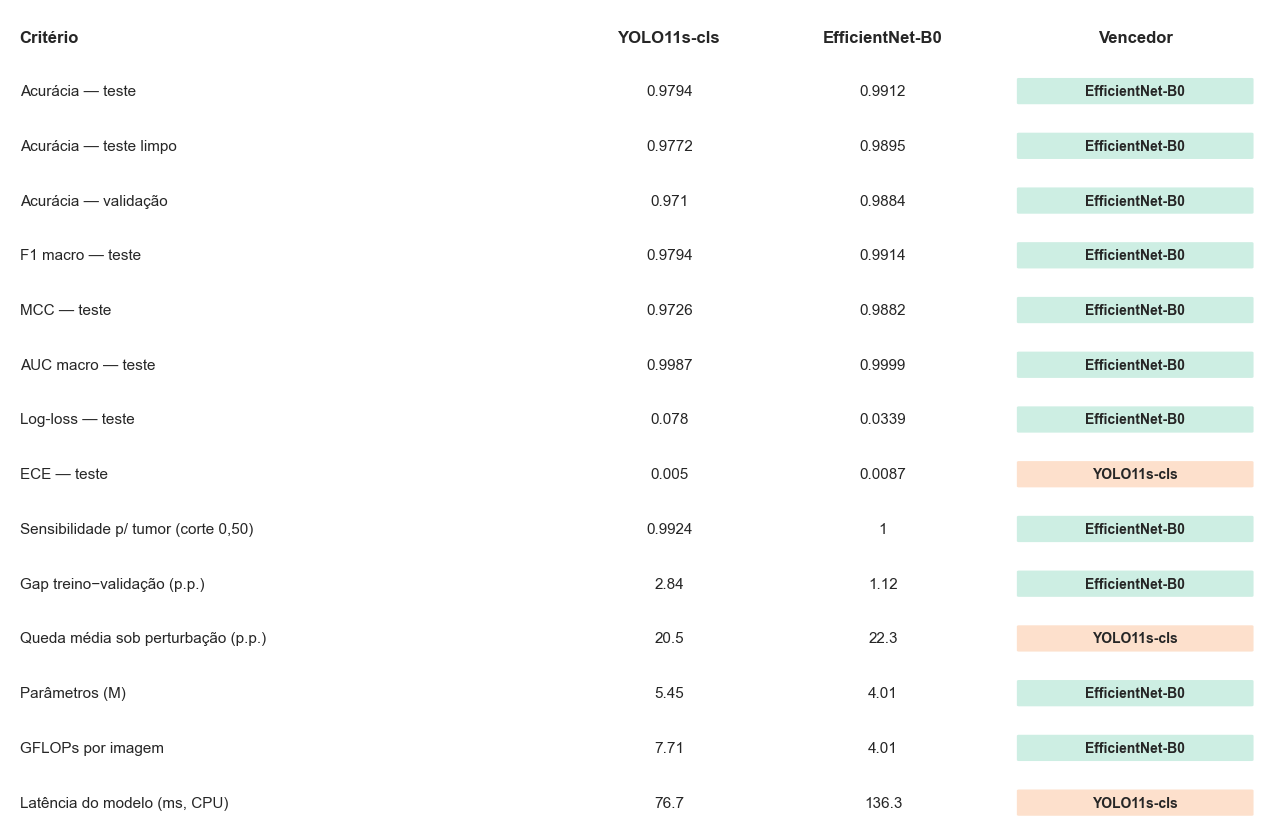

salvo: 17_placar_final.png


In [19]:
def val(m, k): return NUM[k.replace("{m}", m)]
linhas = [("Acurácia — teste", NUM["acc_teste_" + NOME_Y], NUM["acc_teste_" + NOME_C], "max"), ("Acurácia — teste limpo", NUM["acc_teste_limpo_" + NOME_Y], NUM["acc_teste_limpo_" + NOME_C], "max"), ("Acurácia — validação", NUM["acc_val_" + NOME_Y], NUM["acc_val_" + NOME_C], "max"),
          ("F1 macro — teste", NUM["f1_teste_" + NOME_Y], NUM["f1_teste_" + NOME_C], "max"), ("MCC — teste", NUM["mcc_teste_" + NOME_Y], NUM["mcc_teste_" + NOME_C], "max"), ("AUC macro — teste", NUM["auc_macro_" + NOME_Y], NUM["auc_macro_" + NOME_C], "max"),
          ("Log-loss — teste", NUM["logloss_teste_" + NOME_Y], NUM["logloss_teste_" + NOME_C], "min"), ("ECE — teste", NUM["ece_" + NOME_Y], NUM["ece_" + NOME_C], "min"), ("Sensibilidade p/ tumor (corte 0,50)", NUM["clin_s50_" + NOME_Y], NUM["clin_s50_" + NOME_C], "max"),
          ("Gap treino−validação (p.p.)", NUM["gap_treino_val_pp_" + NOME_Y], NUM["gap_treino_val_pp_" + NOME_C], "min"), ("Queda média sob perturbação (p.p.)", NUM["queda_media_pp_" + NOME_Y], NUM["queda_media_pp_" + NOME_C], "min"),
          ("Parâmetros (M)", NUM["parametros_M_" + NOME_Y], NUM["parametros_M_" + NOME_C], "min"), ("GFLOPs por imagem", NUM["gflops_" + NOME_Y], NUM["gflops_" + NOME_C], "min"), ("Latência do modelo (ms, CPU)", NUM["latencia_ms_" + NOME_Y], NUM["latencia_ms_" + NOME_C], "min")]
PL = pd.DataFrame(linhas, columns=["Critério", NOME_Y, NOME_C, "melhor"])
def vence(r): return "empate" if np.isclose(r[NOME_Y], r[NOME_C], rtol=1e-3) else ((NOME_Y if r[NOME_Y] > r[NOME_C] else NOME_C) if r["melhor"] == "max" else (NOME_Y if r[NOME_Y] < r[NOME_C] else NOME_C))
PL["Vencedor"] = PL.apply(vence, axis=1); PL = PL.drop(columns="melhor"); vit_c = int((PL["Vencedor"] == NOME_C).sum()); vit_y = int((PL["Vencedor"] == NOME_Y).sum()); emp_n = int((PL["Vencedor"] == "empate").sum())
fig, ax = plt.subplots(figsize=(13, 0.5 * len(PL) + 1.6)); ax.axis("off"); ax.set_xlim(0, 13); ax.set_ylim(0, len(PL) + 1)
for x_, t_ in ((.1, "Critério"), (6.8, NOME_Y), (9.0, NOME_C), (11.6, "Vencedor")): ax.text(x_, len(PL) + .4, t_, fontweight="bold", fontsize=12, ha="left" if x_ < 6 else "center")
for r_, (_, r) in enumerate(PL.iterrows()):
    y_ = len(PL) - r_ - .5; ax.text(.1, y_, r["Critério"], va="center", fontsize=11); ax.text(6.8, y_, f"{r[NOME_Y]:.4g}", ha="center", va="center", fontsize=11); ax.text(9.0, y_, f"{r[NOME_C]:.4g}", ha="center", va="center", fontsize=11)
    cor = {NOME_Y: "#fde0cc", NOME_C: "#cdeee3", "empate": "#eeeeee"}[r["Vencedor"]]; ax.add_patch(mpatches.FancyBboxPatch((10.4, y_ - .22), 2.4, .44, boxstyle="round,pad=0.02", fc=cor, ec="none")); ax.text(11.6, y_, r["Vencedor"], ha="center", va="center", fontsize=10, fontweight="bold")
plt.tight_layout(); reg_tab("17_placar", PL, "Placar final", index=False); NUM.update(placar_cnn=vit_c, placar_yolo=vit_y, placar_empate=emp_n)
salvar("17_placar_final.png", "Placar final: critério a critério",
       "Os principais critérios de qualidade, generalização, robustez e custo, com o valor de cada modelo e quem vence cada um.",
       "Verde (CNN), laranja (YOLO), cinza (empate técnico). O placar é um resumo: cada critério tem peso diferente conforme o uso (por exemplo, latência para uso em tempo real, sensibilidade para triagem).",
       f"A {NOME_C} vence {vit_c} critérios, o {NOME_Y} vence {vit_y} e {emp_n} empatam. O {NOME_Y} vence: {', '.join(PL[PL['Vencedor'] == NOME_Y]['Critério']) or 'nenhum'}. A {NOME_C} vence: {', '.join(PL[PL['Vencedor'] == NOME_C]['Critério']) or 'nenhum'}.")

In [20]:
conc = f"""# Conclusão da comparação — {NOME_Y} × {NOME_C}

**Desempenho.** No teste ({len(Y['test'])} imagens), {NOME_C} acerta {pp(NUM['acc_teste_'+NOME_C])} ({NUM['erros_teste_'+NOME_C]} erros) e {NOME_Y} {pp(NUM['acc_teste_'+NOME_Y])} ({NUM['erros_teste_'+NOME_Y]} erros); no teste limpo (sem quase-duplicatas), {pp(NUM['acc_teste_limpo_'+NOME_C])} e {pp(NUM['acc_teste_limpo_'+NOME_Y])}. AUC macro {NUM['auc_macro_'+NOME_C]:.4f} contra {NUM['auc_macro_'+NOME_Y]:.4f}; log-loss {NUM['logloss_teste_'+NOME_C]:.3f} contra {NUM['logloss_teste_'+NOME_Y]:.3f}.

**A diferença é real?** Diferença de acurácia (CNN − YOLO) de {NUM['dif_acc_pp']:+.2f} p.p. (IC 95% [{NUM['ic_dif_inf_pp']:+.2f}; {NUM['ic_dif_sup_pp']:+.2f}]); McNemar p = {NUM['mcnemar_p_teste']:.3f} → {veredito}. Na validação (1379 imagens), p = {NUM['mcnemar_p_val']:.2g}. Em 50 dobras do teste, a CNN vence em {NUM['dobras_cnn_vence_pct']:.0f}% e perde em {NUM['dobras_yolo_vence_pct']:.0f}%.

**Generalização.** Gap treino−validação de {NUM['gap_treino_val_pp_'+NOME_C]:.2f} p.p. (CNN) e {NUM['gap_treino_val_pp_'+NOME_Y]:.2f} p.p. (YOLO): variância baixa nos dois; validação ≈ teste.

**Clínico.** Com o corte 0,50: sensibilidade {NUM['clin_s50_'+NOME_C]:.3f} ({NUM['clin_fn50_'+NOME_C]} falsos negativos) na CNN e {NUM['clin_s50_'+NOME_Y]:.3f} ({NUM['clin_fn50_'+NOME_Y]} falsos negativos) no YOLO.

**Robustez.** Queda média de {NUM['queda_media_pp_'+NOME_C]:.1f} p.p. (CNN) e {NUM['queda_media_pp_'+NOME_Y]:.1f} p.p. (YOLO); os dois falham com ruído e desfoque forte; só o YOLO falha também com JPEG severo.

**Eficiência.** A CNN é menor ({NUM['parametros_M_'+NOME_C]:.1f} M × {NUM['parametros_M_'+NOME_Y]:.1f} M de parâmetros), mas mais lenta na CPU ({NUM['latencia_ms_'+NOME_C]:.0f} ms × {NUM['latencia_ms_'+NOME_Y]:.0f} ms).

**Complementaridade.** {NUM['erros_ambos']} imagens erradas pelos dois, {NUM['erros_so_cnn']} só pela CNN e {NUM['erros_so_yolo']} só pelo YOLO; o ensemble chega a {pp(NUM['acc_ensemble'])}.

**Placar.** CNN {vit_c} × YOLO {vit_y} ({emp_n} empates). Checklist: CNN {NUM['checklist_ok_'+NOME_C]}/{NUM['checklist_total']} OK; YOLO {NUM['checklist_ok_'+NOME_Y]}/{NUM['checklist_total']} OK.
"""
(PASTA / "conclusao_comparacao.md").write_text(conc, encoding="utf-8"); print(conc)
(PASTA / "legendas.json").write_text(json.dumps(sorted(LEG, key=lambda l: l["arquivo"]), ensure_ascii=False, indent=1), encoding="utf-8")
(PASTA / "tabelas.json").write_text(json.dumps(TABS, ensure_ascii=False), encoding="utf-8")
(PASTA / "numeros_chave.json").write_text(json.dumps(NUM, ensure_ascii=False, default=str), encoding="utf-8"); pd.DataFrame({"valor": pd.Series(NUM)}).to_csv(PASTA / "numeros_chave.csv", encoding="utf-8-sig")
(PASTA / "tamanhos.json").write_text(json.dumps({l["arquivo"]: list(Image.open(FIG / l["arquivo"]).size) for l in LEG}), encoding="utf-8")
print(f"\n{len(LEG)} figuras em {FIG}"); [print(" -", l["arquivo"]) for l in sorted(LEG, key=lambda l: l["arquivo"])]

# Conclusão da comparação — YOLO11s-cls × EfficientNet-B0

**Desempenho.** No teste (681 imagens), EfficientNet-B0 acerta 99,1% (6 erros) e YOLO11s-cls 97,9% (14 erros); no teste limpo (sem quase-duplicatas), 99,0% e 97,7%. AUC macro 0.9999 contra 0.9987; log-loss 0.034 contra 0.078.

**A diferença é real?** Diferença de acurácia (CNN − YOLO) de +1.17 p.p. (IC 95% [+0.15; +2.35]); McNemar p = 0.057 → limítrofe: o IC do bootstrap exclui zero por pouco, mas o McNemar não é significativo a 5%. Na validação (1379 imagens), p = 3e-06. Em 50 dobras do teste, a CNN vence em 74% e perde em 6%.

**Generalização.** Gap treino−validação de 1.12 p.p. (CNN) e 2.84 p.p. (YOLO): variância baixa nos dois; validação ≈ teste.

**Clínico.** Com o corte 0,50: sensibilidade 1.000 (0 falsos negativos) na CNN e 0.992 (4 falsos negativos) no YOLO.

**Robustez.** Queda média de 22.3 p.p. (CNN) e 20.5 p.p. (YOLO); os dois falham com ruído e desfoque forte; só o YOLO falha também com JPEG severo.

**Eficiência.*

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]